# <p style="background-color:green; font-family:calibri; color:white; font-size:150%; text-align:center; border-radius:15px 50px;">Capstone Project | Fraud Detection </p>

The company aims to improve the security of its mobile financial transaction system by identifying and preventing fraudulent transactions. The occurrence of fraudulent activities can result in financial losses, reduced customer trust, and security concerns.

The main challenge is to distinguish between legitimate and fraudulent transactions accurately while minimizing incorrect predictions. Missing a fraudulent transaction can lead to financial losses, whereas incorrectly flagging a genuine transaction can cause customer inconvenience and operational costs.

Therefore, the objective of this project is to develop a reliable machine learning-based fraud detection system that can identify suspicious transactions, minimize financial risks, protect genuine customers, and improve the overall security of mobile financial transactions.

<div style="border-radius:10px; padding: 15px; background-pink: #facfc8; font-size:120%; text-align:left">

<h3 align="left"><font color=Orange>Problem:</font></h3>

In this project, we explore a financial transactions dataset containing various transaction-related features, including transaction amount, transaction type, time step, and account balances. Our goal is to develop a machine learning model capable of accurately identifying fraudulent financial transactions.

Since undetected fraudulent transactions can lead to significant financial losses, our primary focus is on identifying as many fraudulent transactions as possible while maintaining high precision to minimize incorrect fraud alerts. Therefore, precision, recall, and F1-score for the positive class (fraud) are important evaluation metrics.

<div style="border-radius:10px; padding: 15px; background-pink: #facfc8; font-size:115%; text-align:left">

<h3 align="left"><font color=Orange>Objectives:</font></h3>

Explore the Dataset: Understand the dataset, identify patterns, distributions, and relationships among transaction features.

Conduct Extensive Exploratory Data Analysis (EDA): Analyse univariate and bivariate relationships between transaction features and the target variable.

Preprocessing Steps: Remove irrelevant features.

Check and handle missing values and duplicate records.

Identify and analyse outliers.

Analyse balance inconsistencies.

Encode categorical variables.

Scale numerical features where required.

Select relevant features for model building.

Model Building: Establish pipelines for models that require preprocessing and scaling.

Implement classification algorithms including Logistic Regression, SVM, Decision Trees, Random Forest, and Gradient Boosting.

Apply hyperparameter tuning using GridSearchCV to improve model performance.

Evaluate and Compare Model Performance: Use accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC to evaluate and compare different models.

Select the Best Model: Identify the model that provides a good balance between detecting fraudulent transactions and minimizing false fraud alerts.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from scipy.stats import boxcox
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import confusion_matrix,classification_report,accuracy_score,precision_score,recall_score,f1_score,roc_curve,roc_auc_score,average_precision_score

import ipywidgets as widgets
from IPython.display import display, HTML


import warnings
warnings.filterwarnings('ignore')


In [6]:
# Set the resolution of the plotted figures
plt.rcParams['figure.dpi'] = 200

# Configure Seaborn plot styles: Set background color and use dark| grid
sns.set(rc={'axes.facecolor': '#faded9'}, style='darkgrid')

In [8]:
df=pd.read_csv('Fraud_Analysis_Dataset.csv')

In [9]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,1,TRANSFER,181.0,C1305486145,181.0,0.0,C553264065,0.0,0.0,1
1,1,CASH_OUT,181.0,C840083671,181.0,0.0,C38997010,21182.0,0.0,1
2,1,TRANSFER,2806.0,C1420196421,2806.0,0.0,C972765878,0.0,0.0,1
3,1,CASH_OUT,2806.0,C2101527076,2806.0,0.0,C1007251739,26202.0,0.0,1
4,1,TRANSFER,20128.0,C137533655,20128.0,0.0,C1848415041,0.0,0.0,1


In [10]:
df.shape

(11142, 10)

In [11]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud'],
      dtype='str')

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11142 entries, 0 to 11141
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            11142 non-null  int64  
 1   type            11142 non-null  str    
 2   amount          11142 non-null  float64
 3   nameOrig        11142 non-null  str    
 4   oldbalanceOrg   11142 non-null  float64
 5   newbalanceOrig  11142 non-null  float64
 6   nameDest        11142 non-null  str    
 7   oldbalanceDest  11142 non-null  float64
 8   newbalanceDest  11142 non-null  float64
 9   isFraud         11142 non-null  int64  
dtypes: float64(5), int64(2), str(3)
memory usage: 1.1 MB


In [13]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
count,11142.000000,1.114200e+04,1.114200e+04,1.114200e+04,1.114200e+04,1.114200e+04,11142.000000
mean,8.717645,2.131915e+05,9.241173e+05,8.249576e+05,8.883541e+05,1.103211e+06,0.102495
std,16.067479,7.600650e+05,2.143004e+06,2.089894e+06,2.601376e+06,2.982447e+06,0.303312
min,1.000000,2.390000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,2.000000,4.946618e+03,4.270000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
50%,6.000000,1.676126e+04,2.816950e+04,4.420605e+03,0.000000e+00,0.000000e+00,0.000000
75%,7.000000,1.543366e+05,3.040855e+05,1.114126e+05,2.711555e+05,3.186374e+05,0.000000
max,95.000000,1.000000e+07,1.990000e+07,1.300000e+07,3.300000e+07,3.460000e+07,1.000000


## Descriptive statistics
Step
- The average step is approximately 8.7, while the maximum is 95.
- Most transactions occur during the initial steps, but some occur much later.
  
Amount
- The average transaction amount is around ₹2.13 lakh, whereas the median is approximately ₹16,761.
- This large difference indicates that a few high-value transactions increase the average.
  
Old Balance Origin
- The average sender balance before the transaction is around ₹9.24 lakh.
- However, the median is only ₹28,169, showing that most senders have relatively low balances.
  
New Balance Origin
- The median sender balance after the transaction is approximately ₹4,420.
- This suggests that many transactions leave the sender with a very low or zero balance.
  
Old Balance Destination
- At least half of the recipient accounts have a recorded balance of zero before the transaction.

New Balance Destination
- Many recipient accounts still have a recorded balance of zero after the transaction.

In [14]:
df.isna().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.nunique()

step                 95
type                  5
amount            10565
nameOrig          11142
oldbalanceOrg      7806
newbalanceOrig     5914
nameDest           7508
oldbalanceDest     4531
newbalanceDest     2030
isFraud               2
dtype: int64

In [17]:
df.dtypes

step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
dtype: object

## 1. Dataset understanding
Dataset distribution:
- The dataset contains 11,142 transactions.
- There are 10,000 genuine transactions and 1,142 fraudulent transactions.
- Approximately 89.75% of transactions are genuine, while 10.25% are fraudulent.
- This shows that genuine transactions are much higher than fraudulent transactions.

Missing values and duplicates:
- There are no missing values in the dataset.
- No duplicate records were found.
- Therefore, no missing-value treatment or duplicate removal was required.

In [18]:
df['isFraud'].value_counts()

isFraud
0    10000
1     1142
Name: count, dtype: int64

In [19]:
df['isFraud'].value_counts(normalize=True)*100

isFraud
0    89.750494
1    10.249506
Name: proportion, dtype: float64

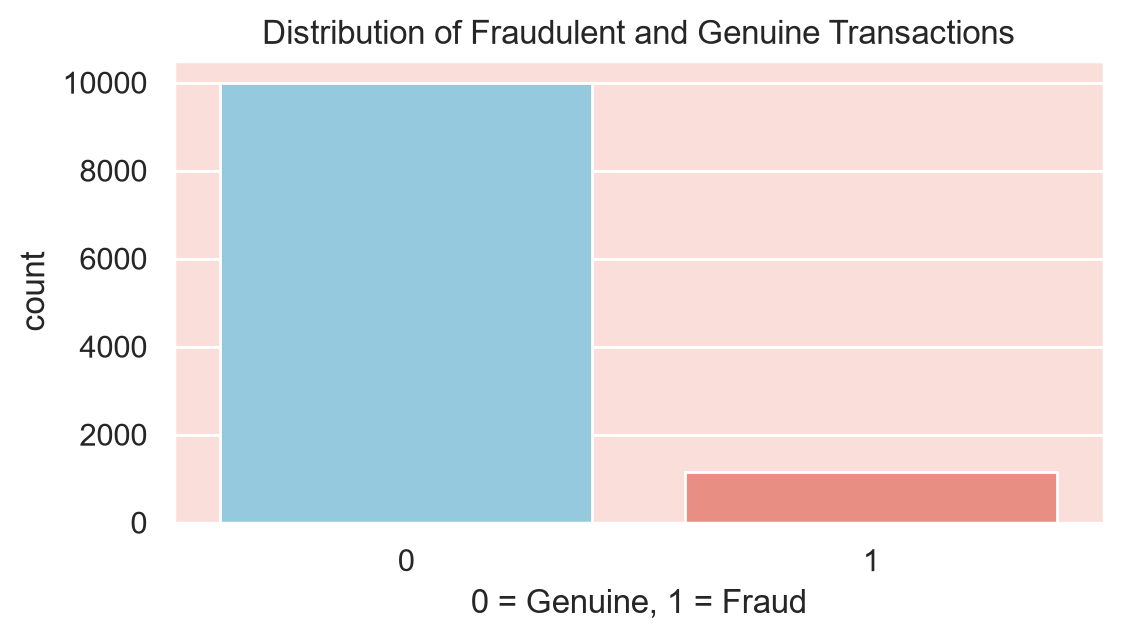

In [20]:
plt.figure(figsize=(6, 3))
sns.countplot(data=df, x='isFraud', hue='isFraud', palette=['skyblue', 'salmon'], legend=False)
plt.title('Distribution of Fraudulent and Genuine Transactions')
plt.xlabel('0 = Genuine, 1 = Fraud')
plt.ylabel('count')

plt.show()

In [21]:
df['type'].value_counts()

type
PAYMENT     5510
CASH_IN     1951
CASH_OUT    1871
TRANSFER    1464
DEBIT        346
Name: count, dtype: int64

In [22]:
df.groupby('type')['isFraud'].sum()

type
CASH_IN       0
CASH_OUT    578
DEBIT         0
PAYMENT       0
TRANSFER    564
Name: isFraud, dtype: int64

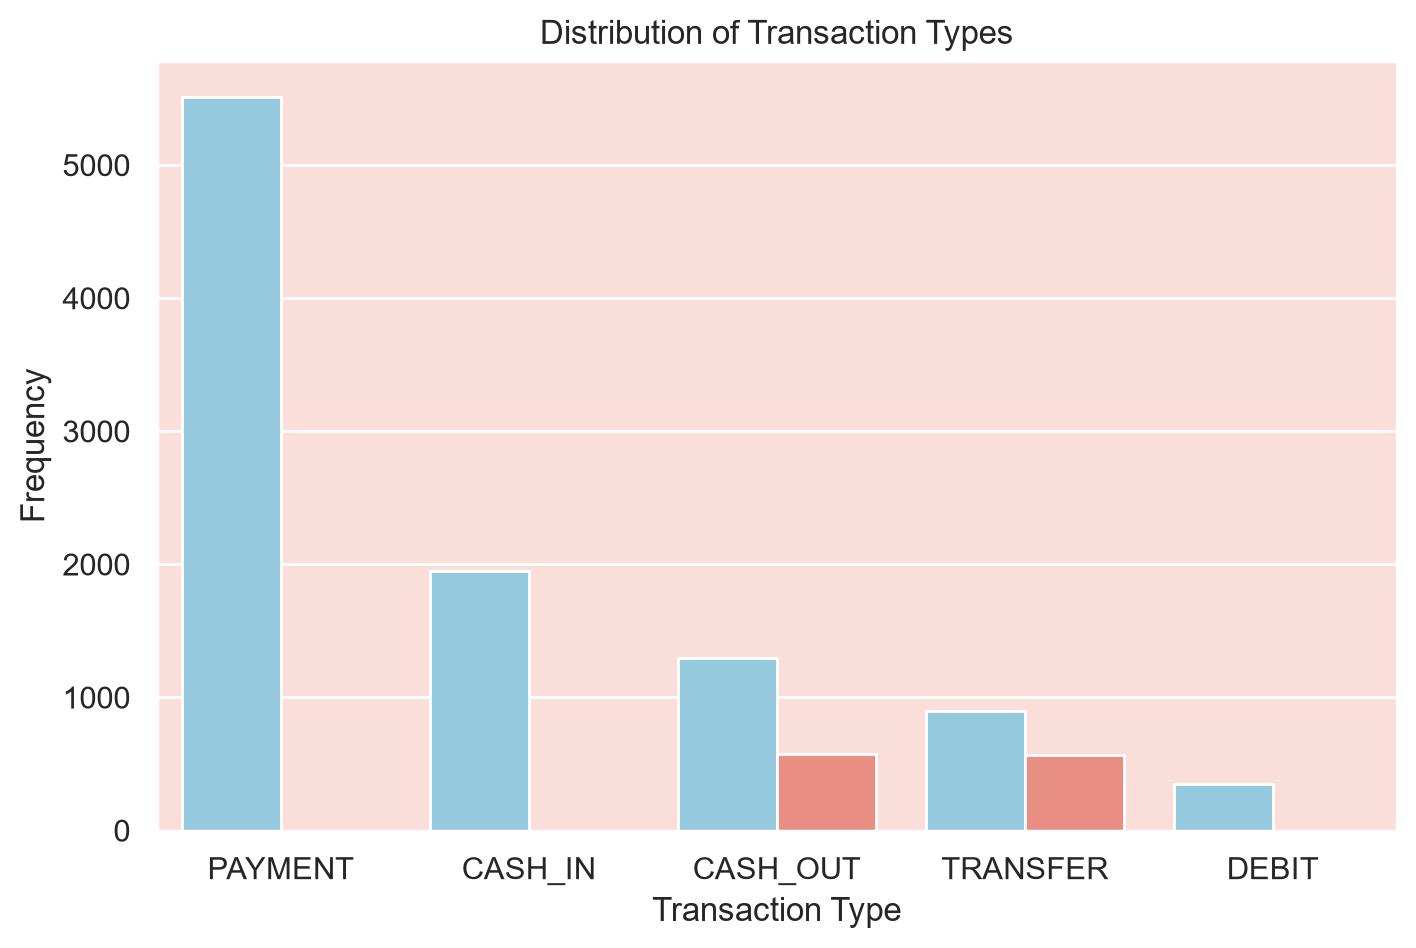

In [23]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='type',
    order=df['type'].value_counts().index,hue='isFraud', palette=['skyblue', 'salmon'], legend=False
    
)

plt.title('Distribution of Transaction Types')
plt.xlabel('Transaction Type')
plt.ylabel('Frequency')

plt.show()

In [24]:
num_features = df.select_dtypes(
    include=['int64', 'float64']
).columns.drop('isFraud', errors='ignore')

cat_features = df.select_dtypes(
    include=['object', 'category']
).columns

print("Numerical Features:", list(num_features))
print("Categorical Features:", list(cat_features))

Numerical Features: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
Categorical Features: ['type', 'nameOrig', 'nameDest']


<div style="border-radius:10px; padding: 15px; background-pink: #facfc8; font-size:120%; text-align:left">

<h3 align="left"><font color=Orange>Inferences:</font></h3>


1. Numerical features and categorical features have been identified separately.
 
2. The numerical features contain transaction-related values such as step, amount, and account balances.
 
3. The categorical features contain non-numerical information, such as transaction type and account details.
 
4. The target variable isFraud has been excluded from numerical features because it is used to predict whether a transaction is fraudulent or genuine.
 
5. This separation will help us apply appropriate techniques during data preprocessing and model building.

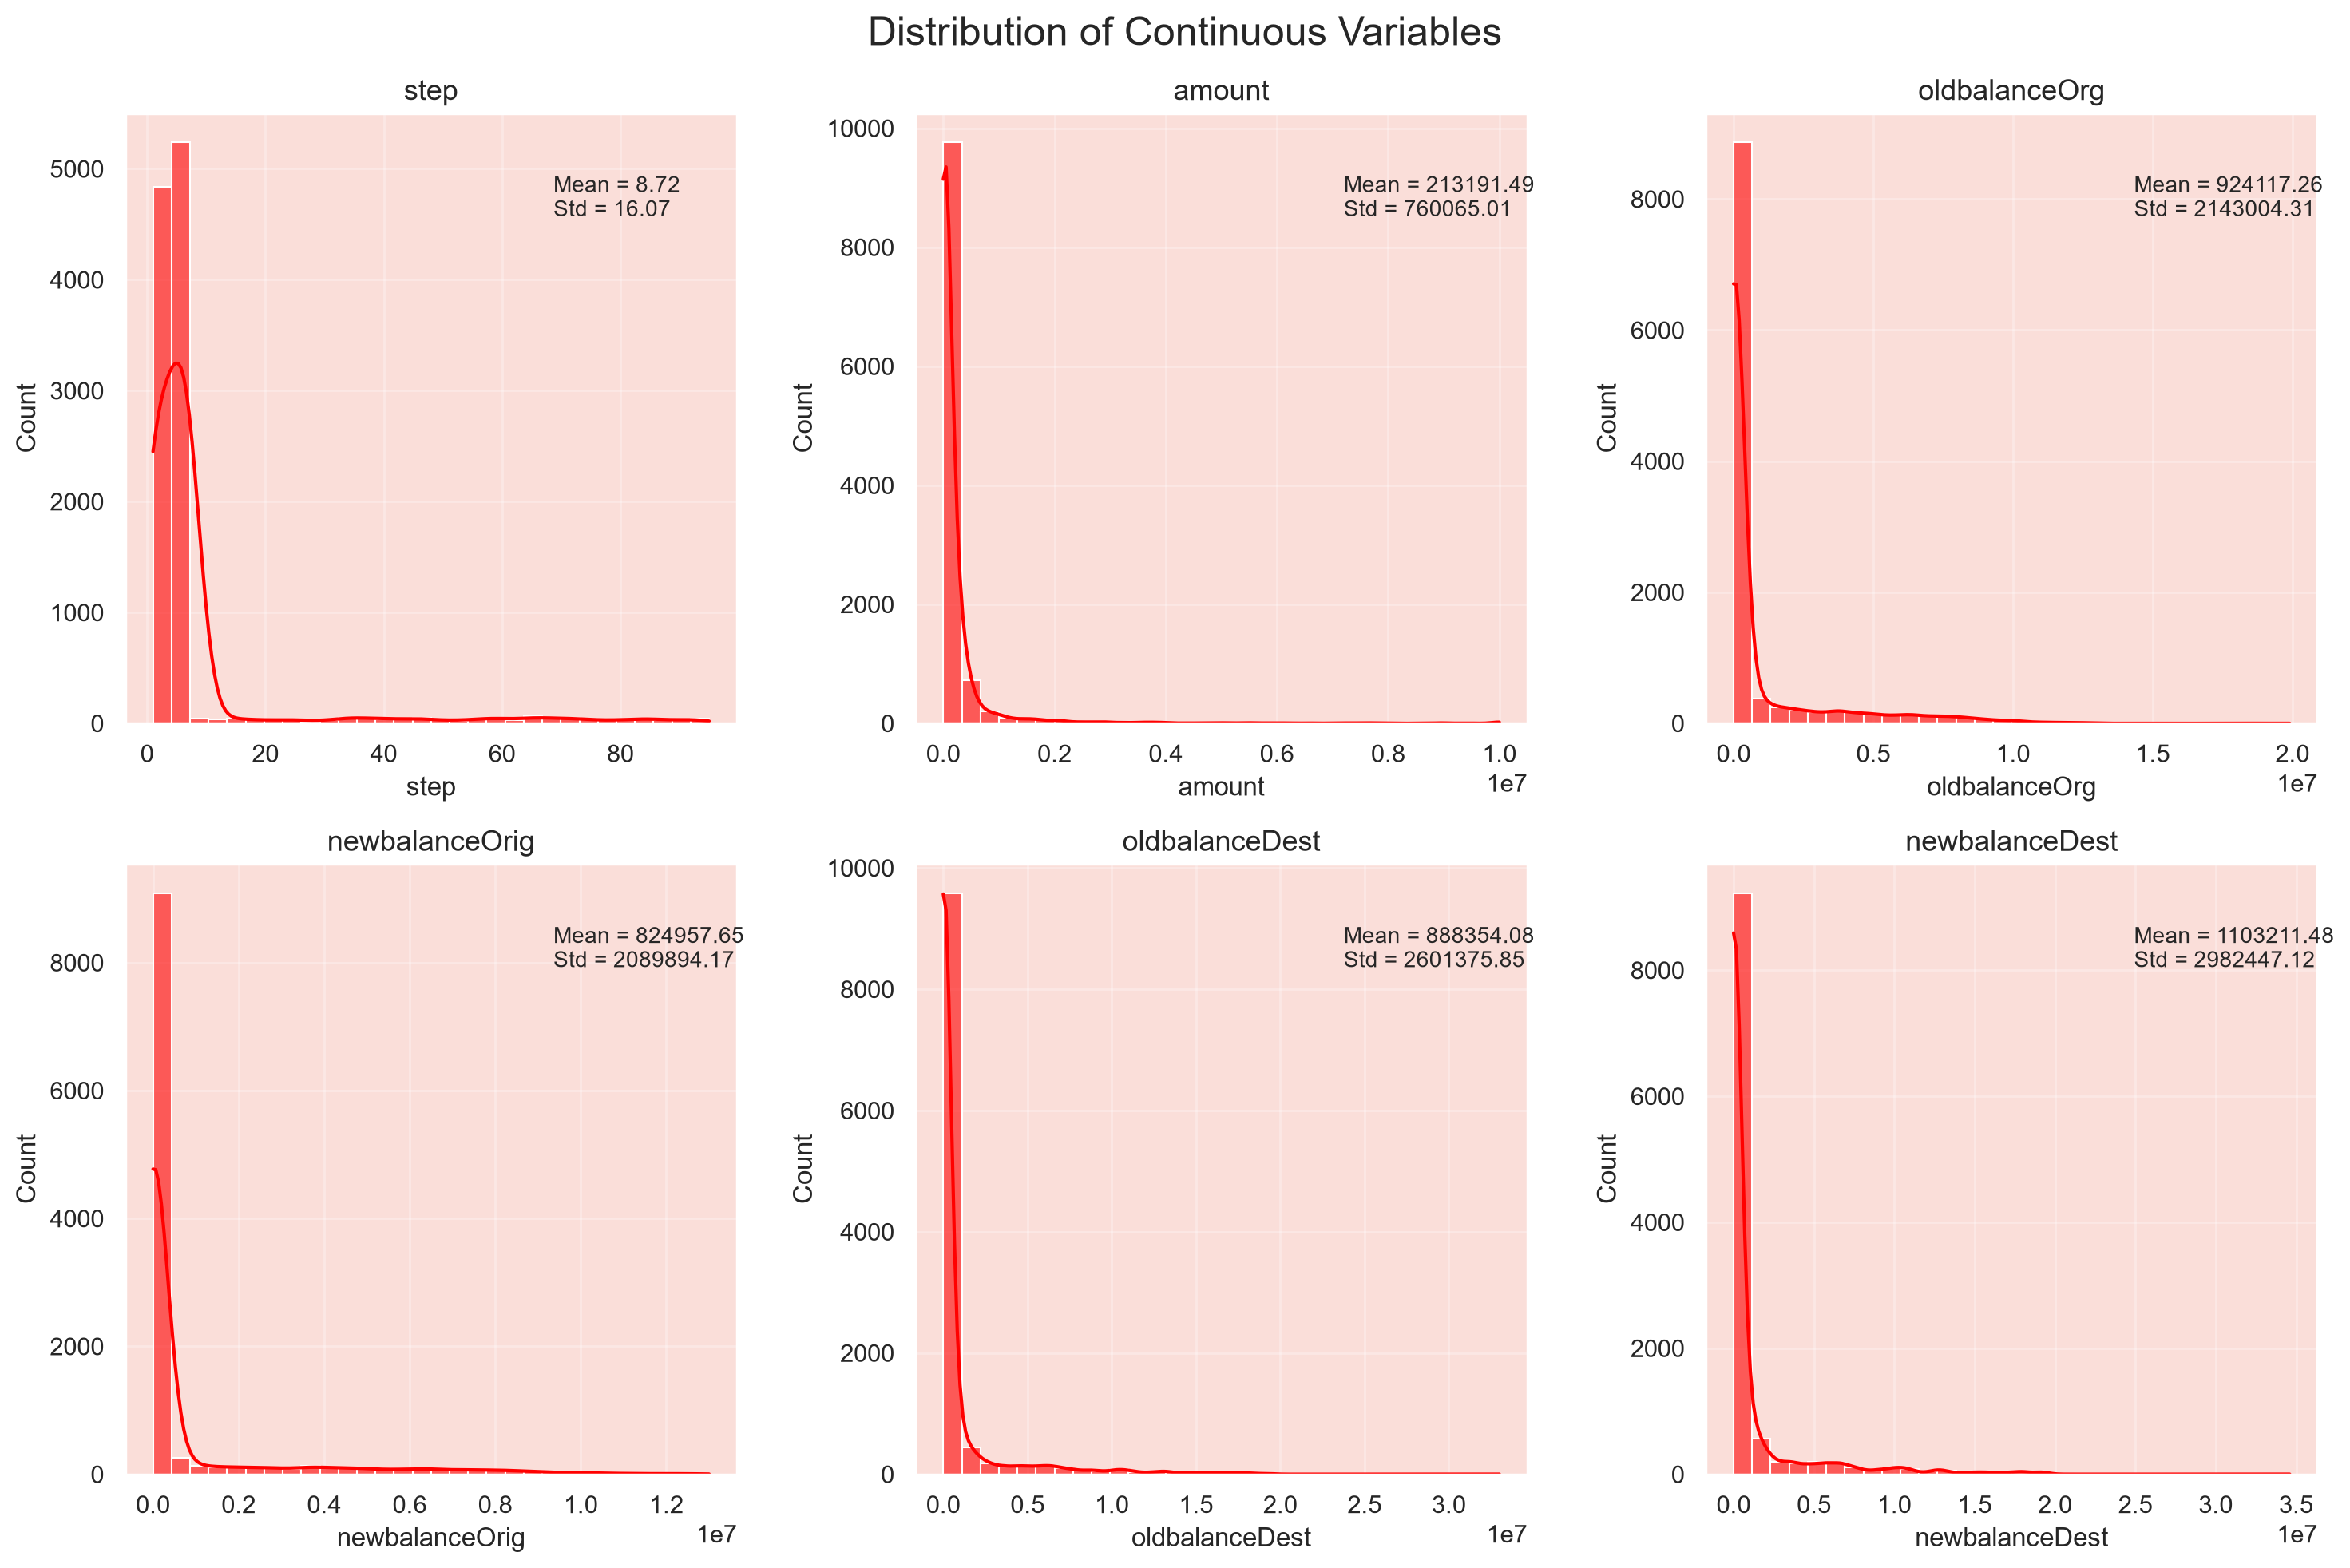

In [25]:
df_num = df[num_features]

n = len(df_num.columns)
fig, ax = plt.subplots((n + 2) // 3, 3, figsize=(15, 5 * ((n + 2) // 3)))

ax = np.array(ax).flatten()

for i, col in enumerate(df_num.columns):

    sns.histplot(
        data=df_num,
        x=col,
        bins=30,
        kde=True,
        ax=ax[i],
        color='red',
        alpha=0.6
    )

    ax[i].set_title(col, fontsize=13)
    ax[i].set_xlabel(col)
    ax[i].set_ylabel('Count')
    ax[i].grid(alpha=0.3)

    textstr = f"Mean = {df_num[col].mean():.2f}\nStd = {df_num[col].std():.2f}"

    ax[i].text(
        0.70, 0.90, textstr,
        transform=ax[i].transAxes,
        fontsize=10,
        verticalalignment='top'
    )

for j in range(n, len(ax)):
    ax[j].axis('off')

plt.suptitle('Distribution of Continuous Variables', fontsize=18)
plt.tight_layout()
plt.show()

<div style="border-radius:10px; padding: 15px; background-pink: #facfc8; font-size:120%; text-align:left">

<h3 align="left"><font color=Orange>Inferences from Distribution of Continuous Variables:</font></h3>


1. Step: Most transactions are concentrated in the early steps, while very few transactions occur in later steps.

2. Amount: Most transactions have smaller amounts, while a few transactions have very high amounts.

3. Old Balance (Origin): Most sender accounts have low initial balances, while a few accounts have very high balances.

4. New Balance (Origin): Most sender accounts have low balances after the transaction, with a few accounts having very high balances.

5. Old Balance (Destination): Most destination accounts have low initial balances, while a few accounts have significantly higher balances.

6. New Balance (Destination): Most destination accounts have low balances after the transaction, while a few have very high balances.

7. All continuous variables are right-skewed, as most values are concentrated on the left side of the graphs.


8. The distributions show the presence of extreme values and potential outliers.
  
9. The mean and standard deviation are relatively high due to large variations in transaction amounts and account balances.


10. The data is not normally distributed.












Do you like this personality?

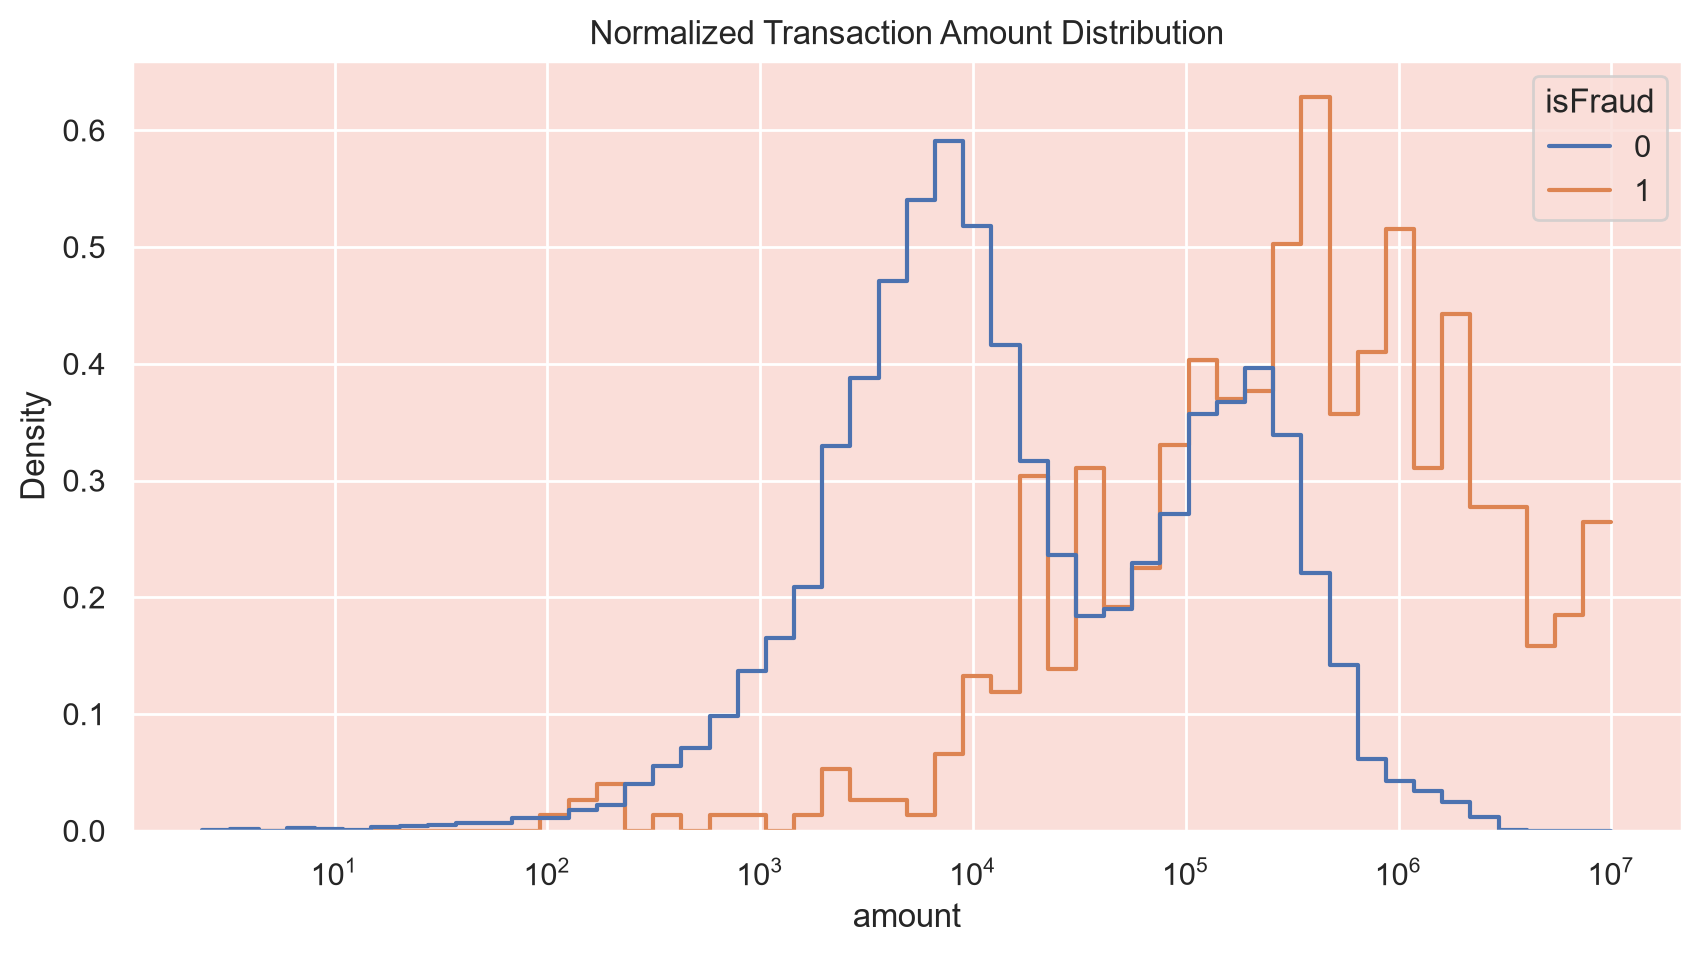

In [26]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x='amount',
    hue='isFraud',
    bins=50,
    stat='density',
    common_norm=False,
    log_scale=True,
    element='step',
    fill=False
)

plt.title('Normalized Transaction Amount Distribution')
plt.show()

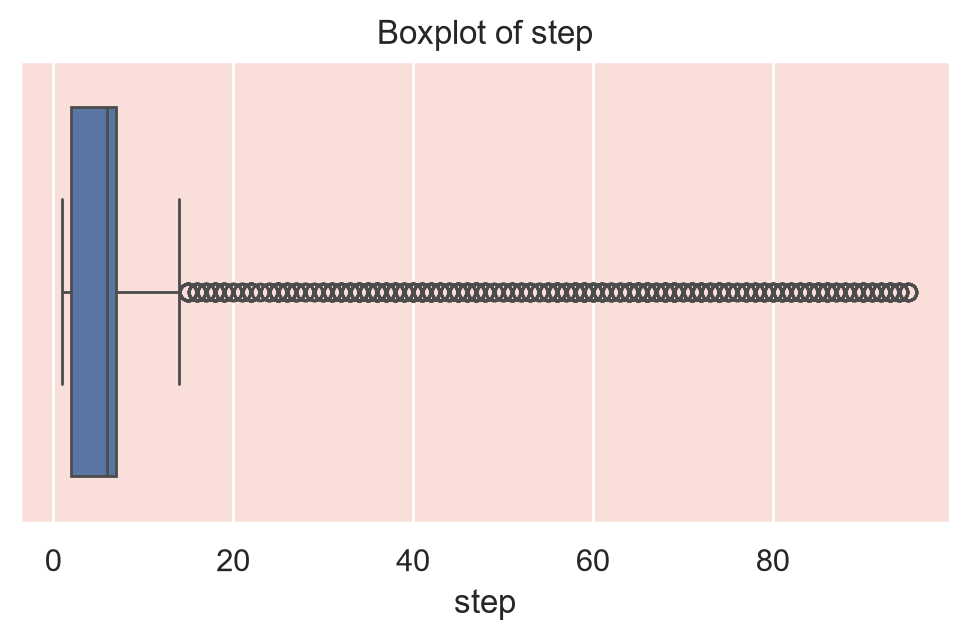

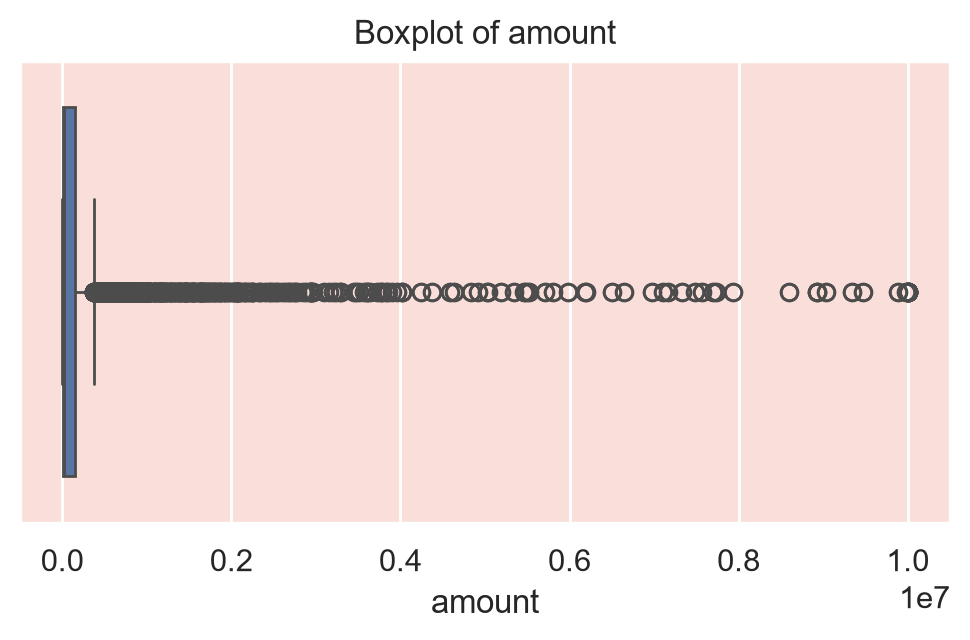

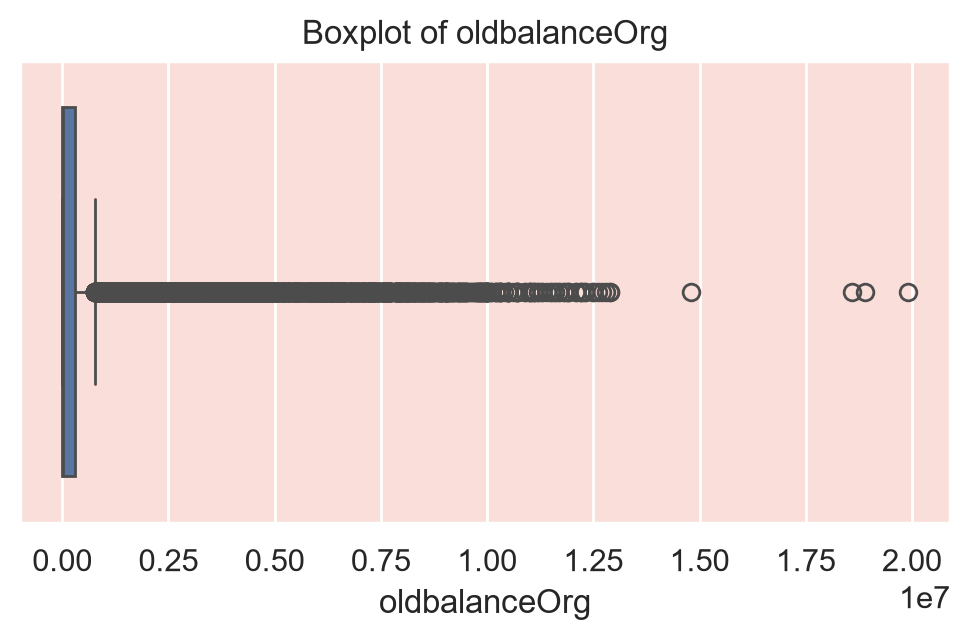

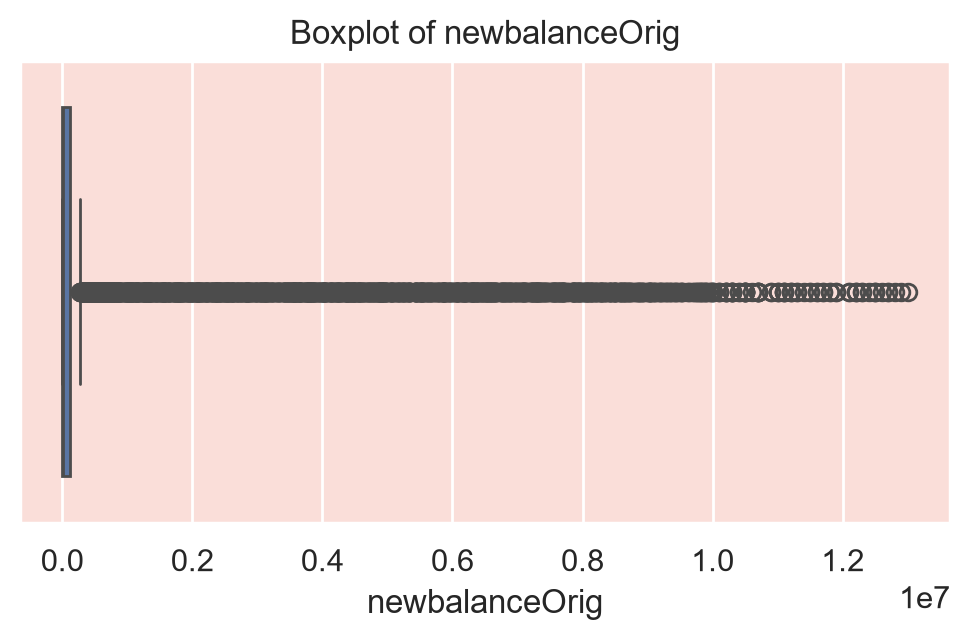

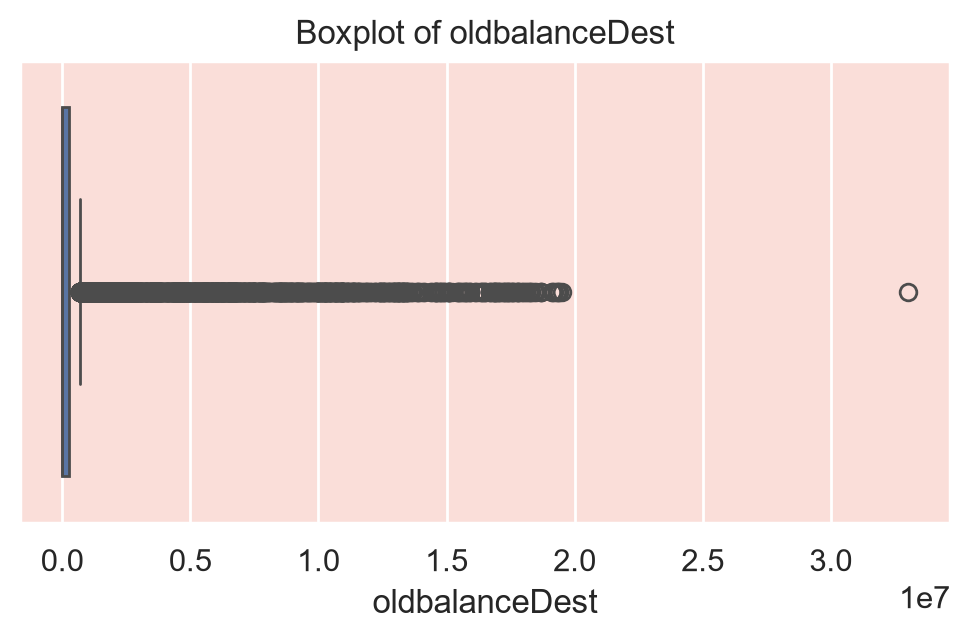

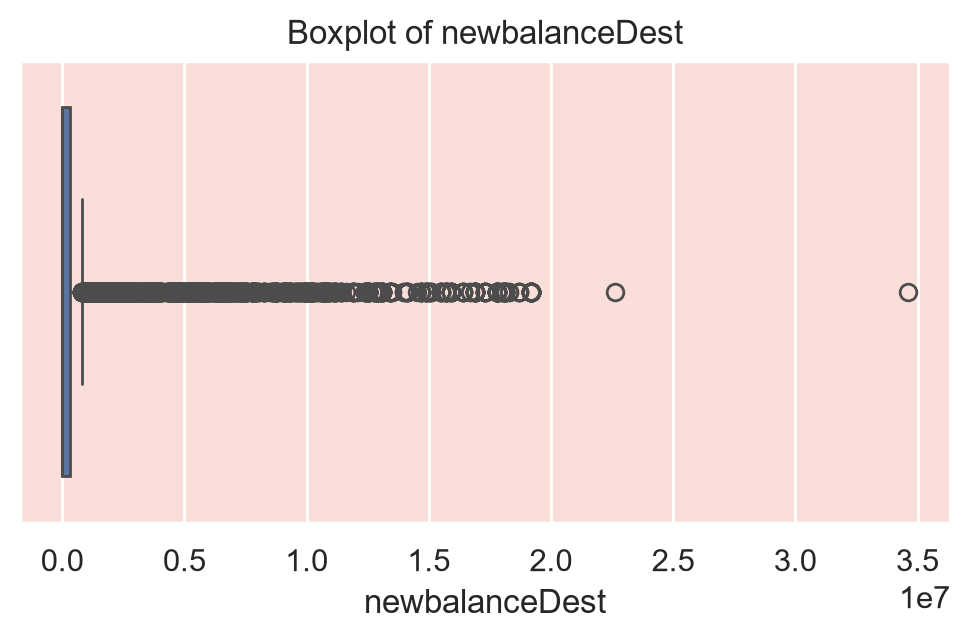

In [27]:
for col in num_features:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [29]:
df[num_features].describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
count,11142.000000,1.114200e+04,1.114200e+04,1.114200e+04,1.114200e+04,1.114200e+04
mean,8.717645,2.131915e+05,9.241173e+05,8.249576e+05,8.883541e+05,1.103211e+06
std,16.067479,7.600650e+05,2.143004e+06,2.089894e+06,2.601376e+06,2.982447e+06
min,1.000000,2.390000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.000000,4.946618e+03,4.270000e+02,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.000000,1.676126e+04,2.816950e+04,4.420605e+03,0.000000e+00,0.000000e+00
75%,7.000000,1.543366e+05,3.040855e+05,1.114126e+05,2.711555e+05,3.186374e+05
max,95.000000,1.000000e+07,1.990000e+07,1.300000e+07,3.300000e+07,3.460000e+07


1. Step: The average step is approximately 8.7, while the maximum is 95. Most transactions take place in the initial steps, but a few transactions occur much later.

2. Amount: The average transaction amount is around ₹2,13,191, whereas the median is only ₹16,761. This indicates that transaction amounts are highly right-skewed because a few very large transactions increase the average.

3. Old Balance Origin: The average sender's balance before the transaction is approximately ₹9.24 lakh. However, the median is only ₹28,169, indicating that most senders have relatively lower balances, while a few have very high balances.

4. New Balance Origin: The average balance after the transaction is approximately ₹8.25 lakh, while the median is ₹4,420. This suggests that many transactions leave the sender with a very low or zero balance.

5. Old Balance Destination: The median destination balance before the transaction is zero. This indicates that at least half of the recipient accounts have zero balance before receiving the transaction.

6. New Balance Destination: The median destination balance after the transaction is also zero. This suggests that many recipient accounts still have zero recorded balance after the transaction.

In [30]:
#Fraud percentage within each transaction type
type_fraud = pd.crosstab(
    df['type'],
    df['isFraud'],
    normalize='index'
) * 100

type_fraud

isFraud,0,1
type,,
CASH_IN,100.000000,0.000000
CASH_OUT,69.107429,30.892571
DEBIT,100.000000,0.000000
PAYMENT,100.000000,0.000000
TRANSFER,61.475410,38.524590


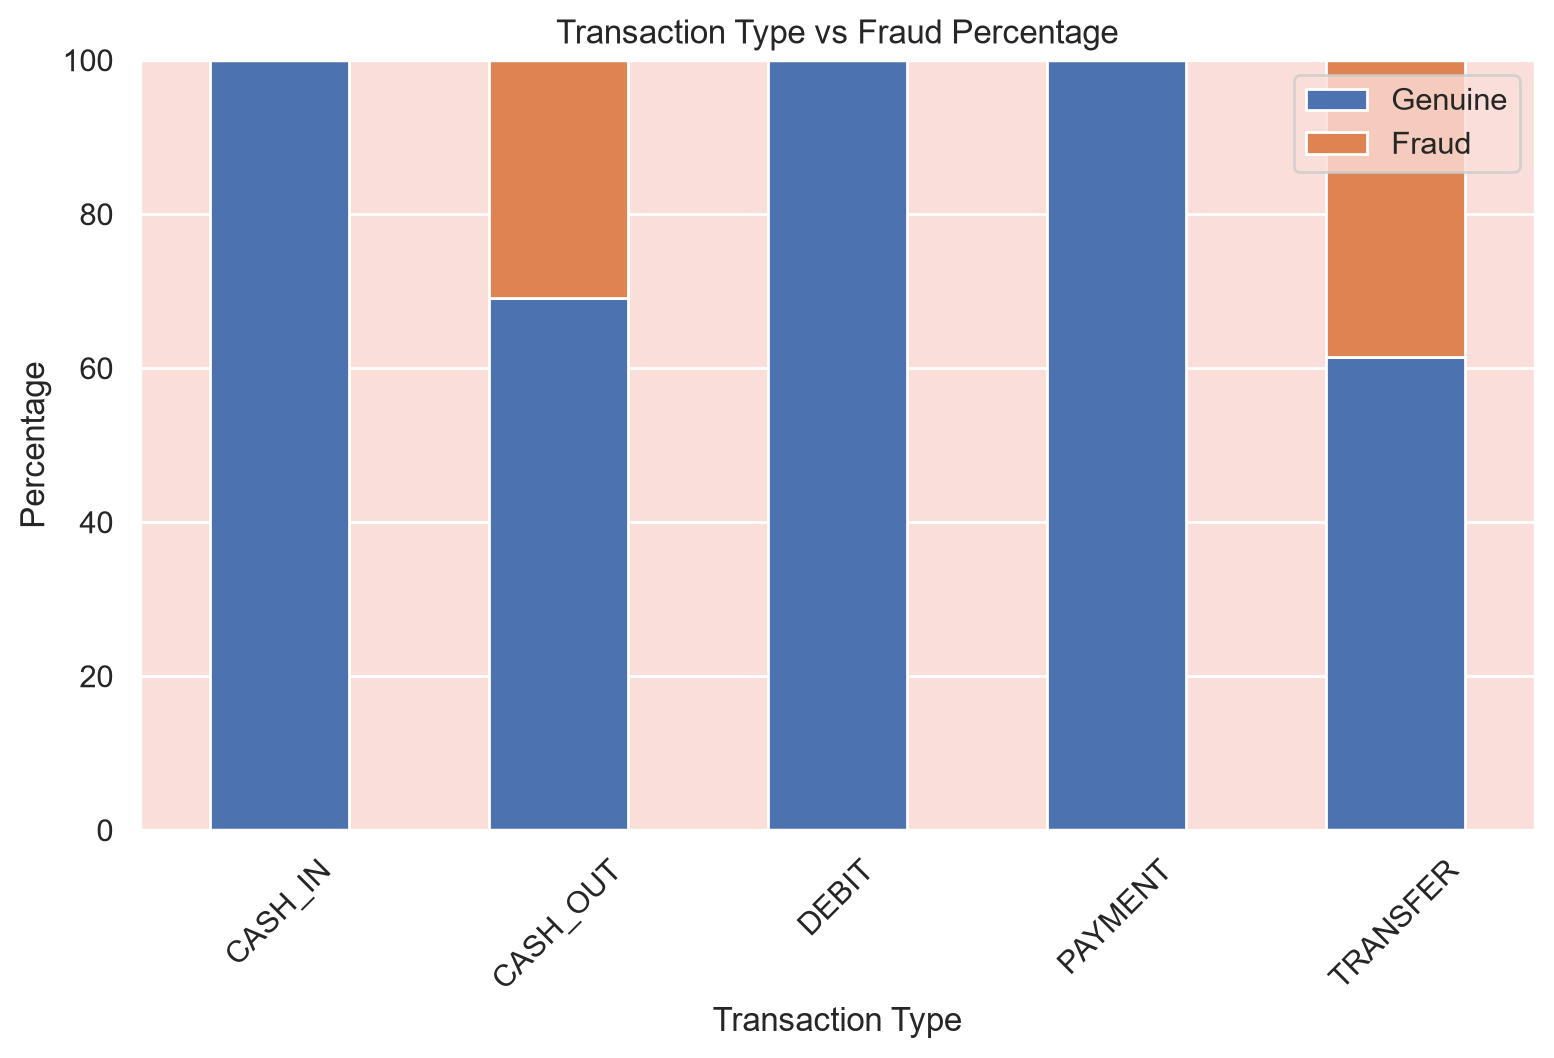

In [31]:
#Visualize the relationship
type_fraud.plot(
    kind='bar',
    stacked=True,
    figsize=(9,5)
)

plt.title('Transaction Type vs Fraud Percentage')
plt.xlabel('Transaction Type')
plt.ylabel('Percentage')
plt.legend(['Genuine', 'Fraud'])
plt.xticks(rotation=45)
plt.show()

Transaction type vs fraud
- Fraudulent transactions are found only in CASH_OUT and TRANSFER categories.
- CASH_OUT has 578 fraudulent transactions.
- TRANSFER has 564 fraudulent transactions.
- Approximately 30.89% of CASH_OUT transactions are fraudulent.
- Approximately 38.52% of TRANSFER transactions are fraudulent.
- CASH_IN, DEBIT and PAYMENT have no fraudulent transactions in this dataset.
- TRANSFER has the highest fraud percentage among all transaction types.
  
Inference: Transaction type is an important feature because fraudulent activities are mainly associated with CASH_OUT and TRANSFER transactions.

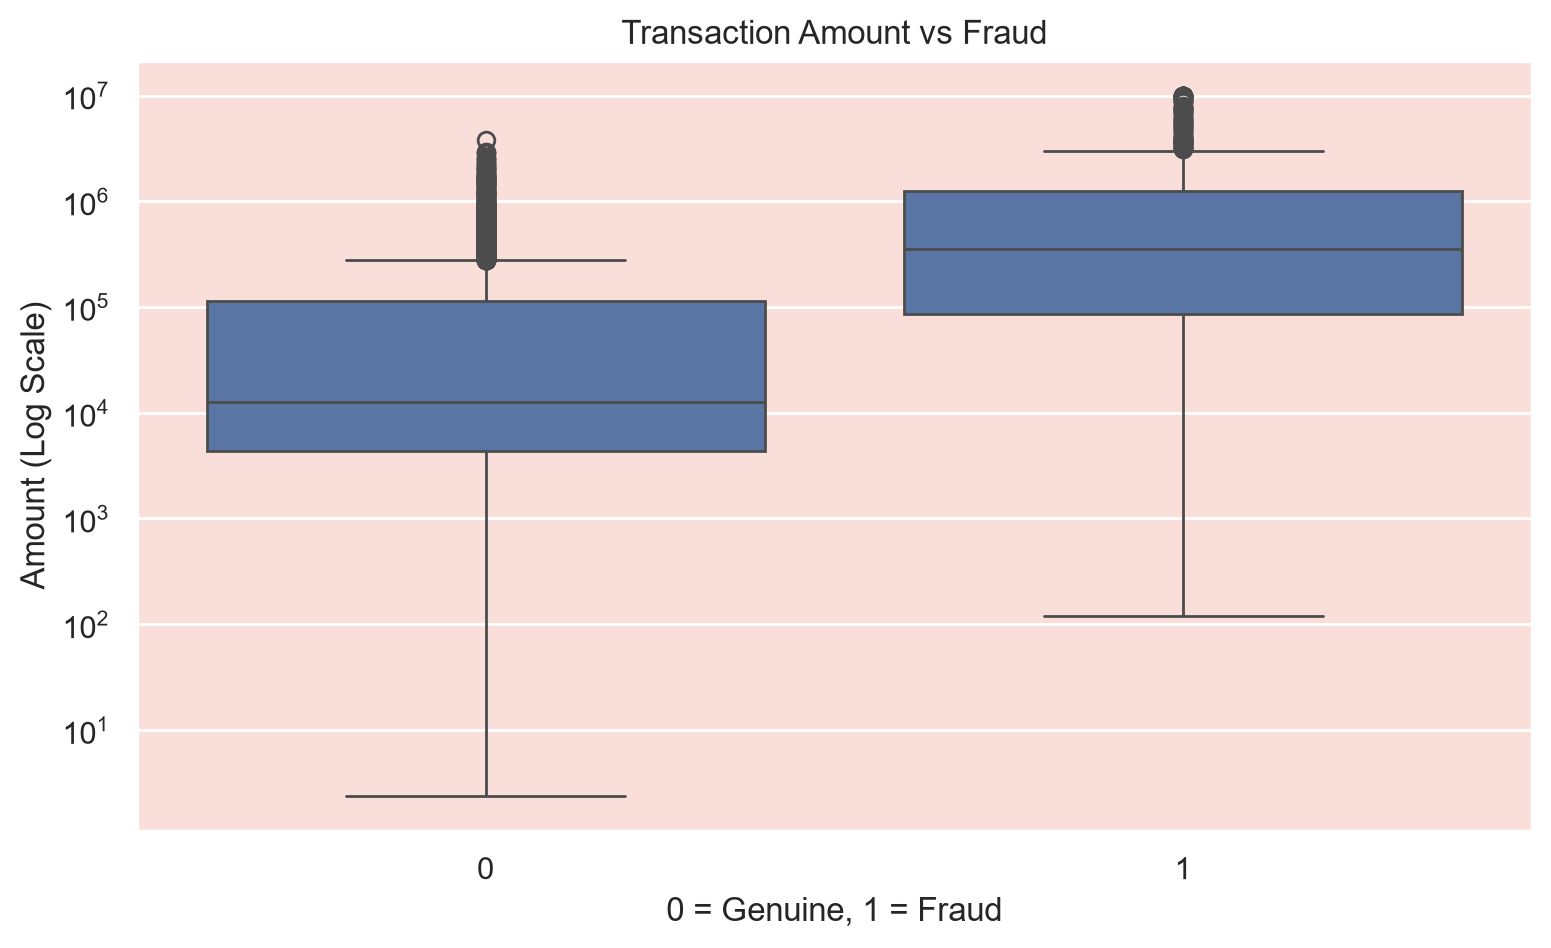

In [32]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x='isFraud',
    y='amount'
)

plt.yscale('log')

plt.title('Transaction Amount vs Fraud')
plt.xlabel('0 = Genuine, 1 = Fraud')
plt.ylabel('Amount (Log Scale)')

plt.show()

## Transaction amount vs fraud
- Fraudulent transactions generally involve higher amounts than genuine transactions.
- The median transaction amount for fraud is higher than that of genuine transactions.
- Genuine transactions show a wider variation in transaction amounts.
- Both categories contain unusually large transactions.
- However, the two distributions overlap, meaning transaction amount alone cannot identify every fraudulent transaction.

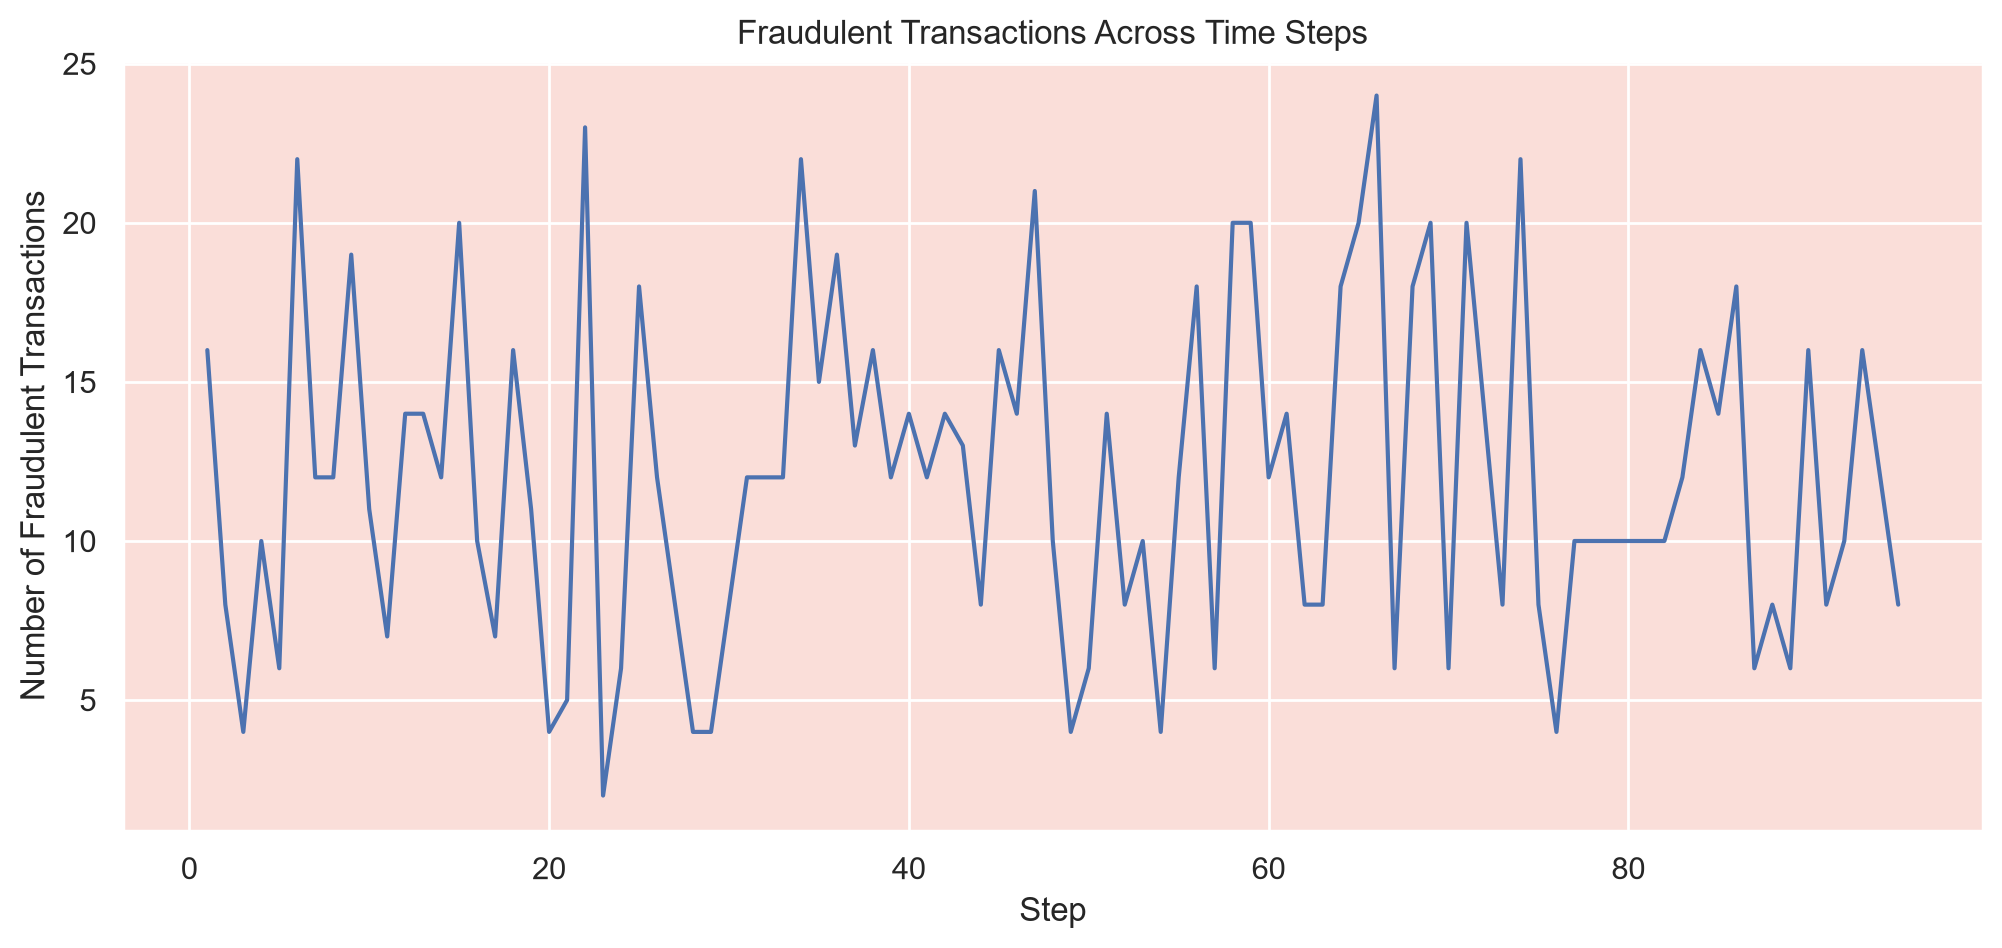

In [34]:
fraud_over_time = df.groupby('step')['isFraud'].sum()

plt.figure(figsize=(12,5))

plt.plot(fraud_over_time.index, fraud_over_time.values)

plt.title('Fraudulent Transactions Across Time Steps')
plt.xlabel('Step')
plt.ylabel('Number of Fraudulent Transactions')

plt.show()

## Fraudulent transactions over time
- Fraudulent transactions occur at different time steps.
- Some time steps have more fraudulent transactions than others.
- The highest number of fraudulent transactions is approximately 24, observed near step 65.
- There is no clear increasing or decreasing trend in the number of fraudulent transactions over time.

In [35]:
fraud_time = df.groupby('step')['isFraud'].agg(
    total_transactions='count',
    fraud_transactions='sum',
    fraud_rate='mean'
)

fraud_time['fraud_rate'] *= 100


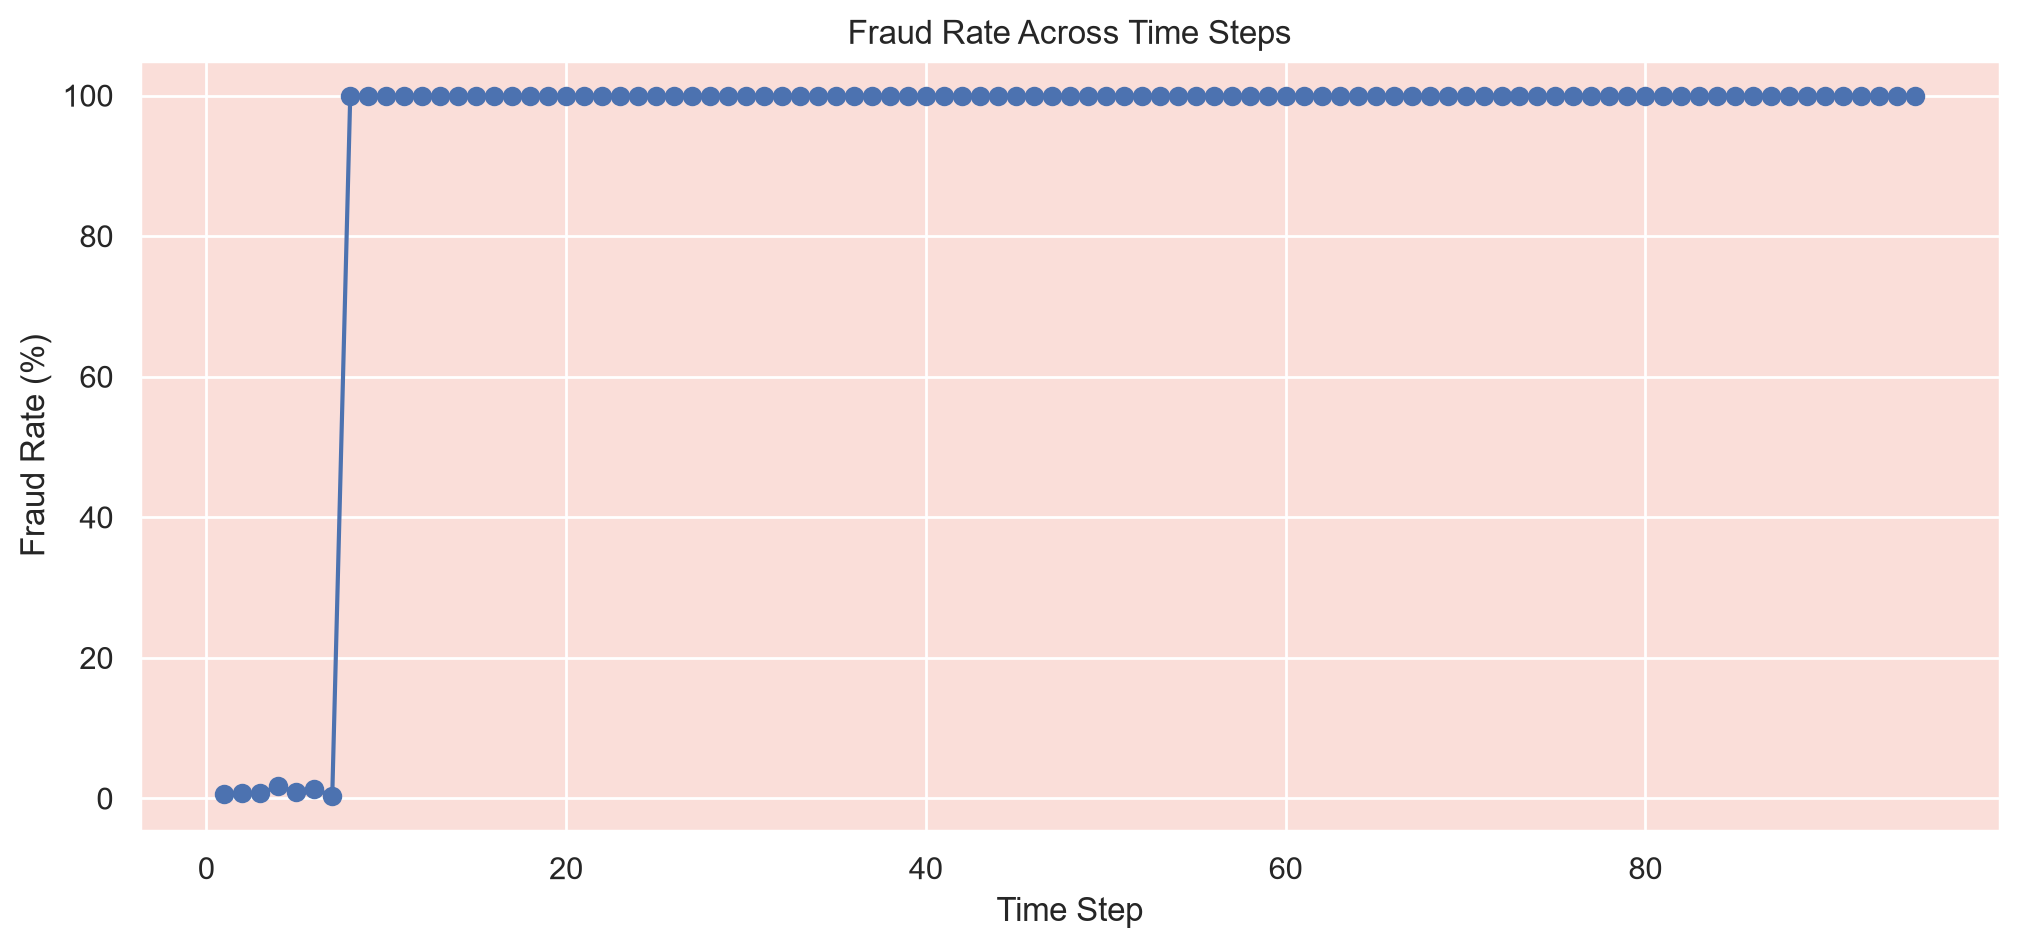

In [36]:
plt.figure(figsize=(12,5))

plt.plot(
    fraud_time.index,
    fraud_time['fraud_rate'],
    marker='o'
)

plt.title('Fraud Rate Across Time Steps')
plt.xlabel('Time Step')
plt.ylabel('Fraud Rate (%)')

plt.show()

## Fraud Rate Across Time Steps – Inferences
- The fraud rate is very low during the initial time steps.
- A sudden increase in fraud rate is observed around step 8.
- The fraud rate appears to remain at 100% in the subsequent time steps.
- This unusual pattern requires further investigation to verify the calculation and understand the distribution of transactions.

In [37]:
df['balance_group'] = pd.cut(
    df['oldbalanceOrg'],
    bins=[-1, 0, 10000, 100000, 1000000, float('inf')],
    labels=['Zero', '0-10K', '10K-1L', '1L-10L', 'Above 10L']
)

In [38]:
df.groupby('balance_group', observed=True)['isFraud'].mean() * 100

balance_group
Zero          0.814332
0-10K         3.950954
10K-1L        7.295010
1L-10L       27.870744
Above 10L    16.083576
Name: isFraud, dtype: float64

In [39]:
df['sender_balance_change'] = (
    df['oldbalanceOrg'] - df['newbalanceOrig']
)

df['receiver_balance_change'] = (
    df['newbalanceDest'] - df['oldbalanceDest']
)

In [40]:
df.groupby('isFraud')[
    ['sender_balance_change', 'receiver_balance_change']
].agg(['mean', 'median', 'std'])

sender_balance_change                            \
                         mean      median           std   
isFraud                                                   
0               -2.480818e+04     538.585  9.963764e+04   
1                1.184692e+06  348705.145  2.033328e+06   

        receiver_balance_change                          
                           mean    median           std  
isFraud                                                  
0                 168010.620135     0.000  1.039986e+06  
1                 625074.346051  3733.035  1.592164e+06

In [41]:
df['sender_balance_error'] = (
    df['sender_balance_change'] - df['amount']
)

df['receiver_balance_error'] = (
    df['receiver_balance_change'] - df['amount']
)

In [42]:
df.groupby('isFraud')[
    ['sender_balance_error', 'receiver_balance_error']
].agg(['mean', 'median', 'std'])

sender_balance_error                          receiver_balance_error  \
                        mean    median            std                   mean   
isFraud                                                                        
0             -126147.908086 -5573.715  263813.427320           66670.891497   
1               -7937.031935     0.000   85459.668523         -567554.586025   

                                 
           median           std  
isFraud                          
0       -6605.920  9.852824e+05  
1       -9439.945  1.593695e+06

In [43]:
df['is_merchant'] = df['nameDest'].str.startswith('M')

df['is_merchant'].value_counts()      

is_merchant
False    5632
True     5510
Name: count, dtype: int64

In [44]:
pd.crosstab(
    df['is_merchant'],
    df['isFraud'],
    normalize='index'
).mul(100).round(2)  ####   Non-merchant recipients account for 20.28% fraudulent transactions within their group.

isFraud,0,1
is_merchant,,
False,79.72,20.28
True,100.00,0.00


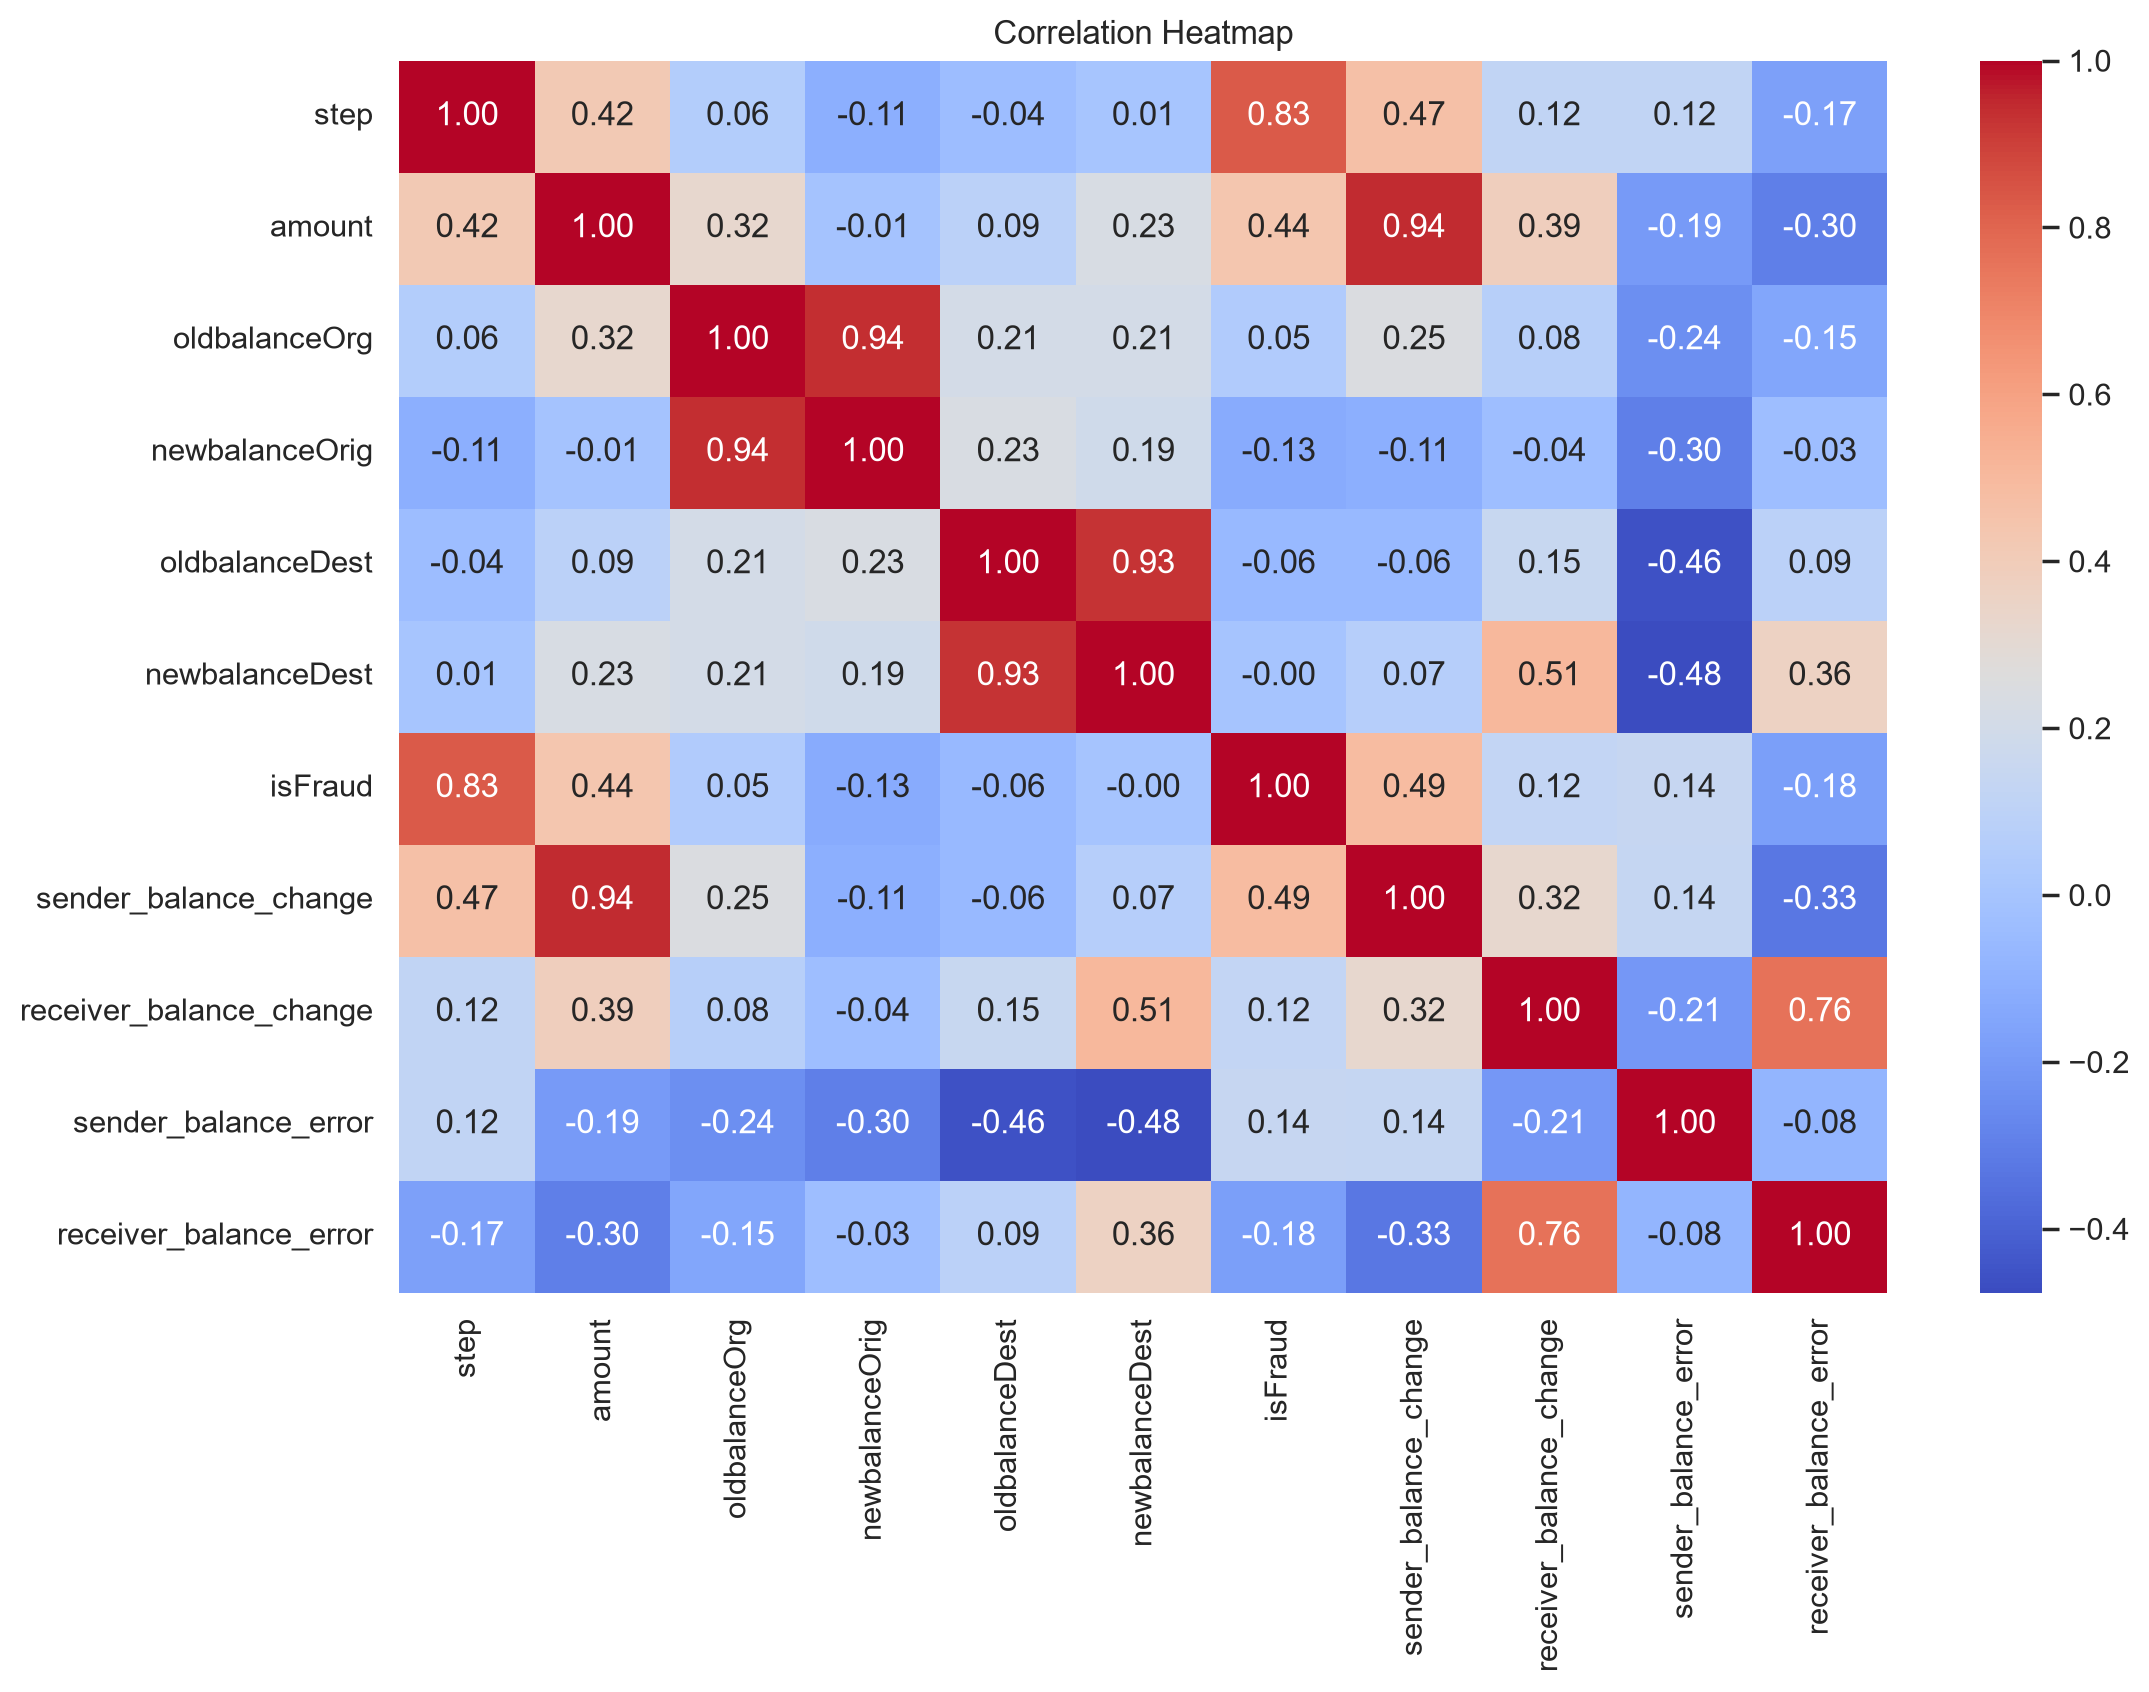

In [45]:
numeric_df = df.select_dtypes(include='number')
plt.figure(figsize=(12,8))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap')
plt.show()

## Correlation analysis
- Correlation helps us understand how numerical features are related to each other.
- Some balance-related features may show relationships because they are connected to the same transaction.
- A high correlation does not necessarily mean that one feature causes changes in another.
- Correlation alone cannot confirm fraudulent activity.

In [46]:
for col in num_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR 

    outliers = df[
        (df[col] < lower_bound)|
        (df[col] > upper_bound)
    ]
    print(f'\nFeatures: {col}')
    print('Lower bound:', lower_bound)
    print('Upper bound:',upper_bound)
    print('Number of Outliers:', len(outliers))


Features: step
Lower bound: -5.5
Upper bound: 14.5
Number of Outliers: 975

Features: amount
Lower bound: -219138.31875000003
Upper bound: 378421.51125000004
Number of Outliers: 1172

Features: oldbalanceOrg
Lower bound: -455060.72
Upper bound: 759573.2
Number of Outliers: 2195

Features: newbalanceOrig
Lower bound: -167118.9525
Upper bound: 278531.5875
Number of Outliers: 2245

Features: oldbalanceDest
Lower bound: -406733.20875
Upper bound: 677888.6812499999
Number of Outliers: 1921

Features: newbalanceDest
Lower bound: -477956.04
Upper bound: 796593.3999999999
Number of Outliers: 2214


Inference
- All numerical features contain outliers.
- The highest number of outliers is present in newbalanceOrig (2,245).
- The lowest number of outliers is present in step (975).
- These outliers may represent genuine high-value transactions rather than incorrect data.
- These extreme values may contain useful information for identifying suspicious transactions.
Decision: We will not remove or cap the outliers because they may carry important information for fraud detection. We will retain them for further analysis and model building.

In [47]:
Q1 = df['amount'].quantile(0.25)
Q3 = df['amount'].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

df['amount_outlier'] = (
    df['amount'] > upper_bound
).astype(int)

df.groupby('amount_outlier')['isFraud'].agg(
    ['count', 'mean']
)

,count,mean
amount_outlier,,
0,9970,0.059880
1,1172,0.465017


# Outlier analysis using IQR
- The dataset contains unusually high transaction amounts.
- Approximately 1,172 transactions are identified as amount outliers.
- Around 46.50% of these outlier transactions are fraudulent.
- In comparison, only around 5.99% of transactions within the upper IQR limit are fraudulent.
- This shows a strong relationship between unusually high transaction amounts and fraud.
- Therefore, high transaction amounts may be useful for identifying suspicious transactions.
- 
Decision: We did not remove or cap the outliers because unusually high transaction amounts may contain important information for fraud detection.

In [48]:
## balance inconsistency indicator
df['expected_newbalanceOrig'] = (
    df['oldbalanceOrg'] - df['amount']
)

In [49]:
df['sender_balance_error'] = (
    df['newbalanceOrig'] - df['expected_newbalanceOrig']
)

In [50]:
df['sender_inconsistent'] = (
    df['sender_balance_error'] != 0
)

df['sender_inconsistent'].value_counts()

sender_inconsistent
True     6982
False    4160
Name: count, dtype: int64

In [51]:
df['sender_inconsistent'].value_counts(normalize=True) * 100

sender_inconsistent
True     62.663795
False    37.336205
Name: proportion, dtype: float64

In [52]:
df['expected_newbalanceDest'] = (
    df['oldbalanceDest'] + df['amount']
)

In [53]:
df['receiver_balance_error'] = (
    df['newbalanceDest'] - df['expected_newbalanceDest']
)

In [54]:
df['receiver_inconsistent'] = (
    df['receiver_balance_error'] != 0
)

df['receiver_inconsistent'].value_counts()

receiver_inconsistent
True     10362
False      780
Name: count, dtype: int64

In [55]:
## relationship between fraud and sender inconsistent
df.groupby('sender_inconsistent')['isFraud'].mean() * 100

sender_inconsistent
False    26.682692
True      0.458321
Name: isFraud, dtype: float64

In [56]:
#### relationship between fraud and receiver inconsistent
df.groupby('receiver_inconsistent')['isFraud'].mean() * 100

receiver_inconsistent
False    43.974359
True      7.710867
Name: isFraud, dtype: float64

# Balance inconsistency analysis

Sender balance inconsistency:
- Approximately 62.66% of transactions have an inconsistent sender balance.
- The fraud rate among transactions with consistent sender balances is approximately 26.68%.
- The fraud rate among transactions with inconsistent sender balances is only 0.46%.
- This suggests that sender balance inconsistency alone is not a reliable indicator of fraud.
- 
Receiver balance inconsistency:
- Transactions with consistent receiver balances show a fraud rate of approximately 43.97%.
- Transactions with inconsistent receiver balances show a fraud rate of approximately 7.71%.
- This indicates that receiver balance inconsistency also has a relationship with fraud in this dataset.
- However, it should not be treated as proof of fraudulent activity.
- 
Overall inference: Balance inconsistencies may help us understand transaction behaviour, but they should not independently determine whether a transaction is fraudulent.

In [57]:
from scipy.stats import ttest_ind

genuine = df[df['isFraud'] == 0]['amount']
fraud = df[df['isFraud'] == 1]['amount']

t_stat, p_value = ttest_ind(
    genuine, fraud, equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -18.148541916325897
P-value: 6.927063561694163e-65


# T-test analysis
- The T-test was performed to compare the average transaction amounts of genuine and fraudulent transactions.
- The average amount of fraudulent transactions is approximately ₹11.93 lakh.
- The average amount of genuine transactions is approximately ₹1.01 lakh.
- The p-value is extremely small (6.93 × 10⁻⁶⁵), which is below 0.05.
- Therefore, there is a statistically significant difference between the average transaction amounts of genuine and fraudulent transactions.
- This supports our earlier finding that fraudulent transactions generally involve higher amounts.
- 
Conclusion: Transaction amount is an important feature for distinguishing between genuine and fraudulent transactions.

In [58]:
print("Genuine Average:", genuine.mean())
print("Fraud Average:", fraud.mean())

print("Difference:", fraud.mean() - genuine.mean())

Genuine Average: 101339.72863799999
Fraud Average: 1192628.9320753065
Difference: 1091289.2034373065


In [59]:
features = [
    'step',
    'type',
    'amount',
    'oldbalanceOrg',
    'oldbalanceDest',
]

X = df[features]
y = df['isFraud']

In [60]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [61]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8913, 5)
X_test: (2229, 5)
y_train: (8913,)
y_test: (2229,)


In [62]:
# Identify columns
num_features = [
    'step',
    'amount',
    'oldbalanceOrg',
    'oldbalanceDest',
]

cat_features = ['type']

# Create transformers
num_transformer = StandardScaler()
cat_transformer = OneHotEncoder(handle_unknown='ignore')

# Column Transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ]
)

# Pipeline
logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

# Train model
logistic_model.fit(X_train, y_train)

# Predictions
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

Confusion Matrix:
[[1938   63]
 [  17  211]]

 Classification Report
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      2001
           1       0.77      0.93      0.84       228

    accuracy                           0.96      2229
   macro avg       0.88      0.95      0.91      2229
weighted avg       0.97      0.96      0.97      2229

Accuracy: 0.9641094661283086
Precision: 0.7700729927007299
f1 score: 0.8406374501992032
Recall: 0.9254385964912281


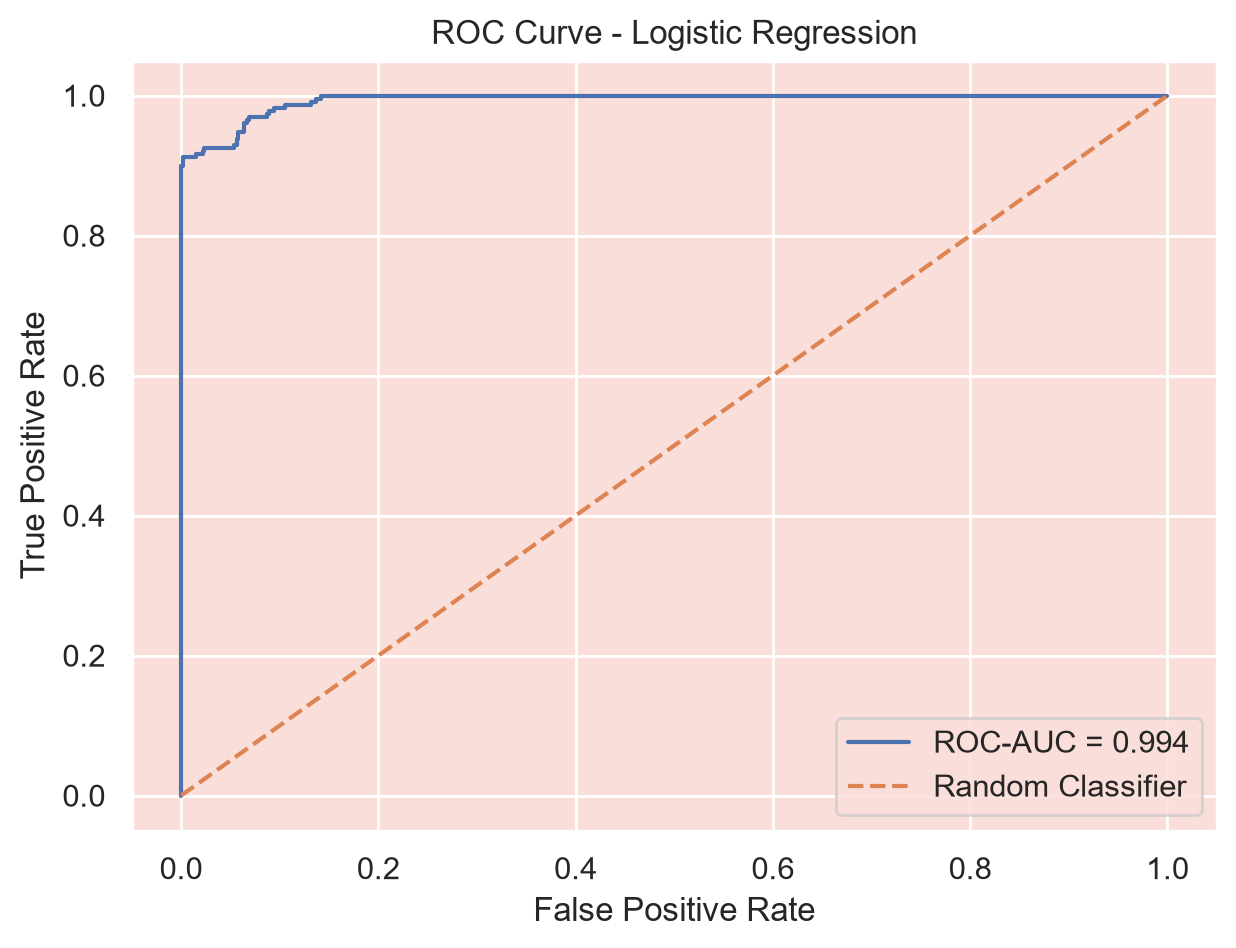

ROC-AUC: 0.9935931157228404
PR-AUC (Average Precision): 0.966699378440325


In [63]:
## Confusion Matrix
cm = confusion_matrix(y_test,y_pred)
print("Confusion Matrix:")
print(cm)

# Classification Report
print("\n Classification Report")
print(classification_report(y_test,y_pred))

## Individual Merics
print("Accuracy:",accuracy_score(y_test,y_pred))
print("Precision:",precision_score(y_test,y_pred))
print("f1 score:",f1_score(y_test,y_pred))
print("Recall:",recall_score(y_test,y_pred))

# ROC Curve and ROC-AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc= roc_auc_score(y_test,y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

print("ROC-AUC:", roc_auc)

# PR-AUC
pr_auc = average_precision_score(y_test, y_prob)
print("PR-AUC (Average Precision):", pr_auc)



In [64]:
# Predictions on training data
y_train_pred = logistic_model.predict(X_train)
y_train_prob = logistic_model.predict_proba(X_train)[:, 1]

# Predictions on testing data
y_test_pred = logistic_model.predict(X_test)
y_test_prob = logistic_model.predict_proba(X_test)[:, 1]


# Function to calculate metrics
def evaluate_model(y_true, y_pred, y_prob):

    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1 Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }


# Evaluate both datasets
train_metrics = evaluate_model(
    y_train, y_train_pred, y_train_prob
)

test_metrics = evaluate_model(
    y_test, y_test_pred, y_test_prob
)


# Comparison table
comparison = pd.DataFrame({
    'Training Data': train_metrics,
    'Testing Data': test_metrics
})

print(comparison.round(4))

           Training Data  Testing Data
Accuracy          0.9654        0.9641
Precision         0.7691        0.7701
Recall            0.9475        0.9254
F1 Score          0.8490        0.8406
ROC-AUC           0.9948        0.9936
PR-AUC            0.9752        0.9667


In [65]:
param_grid_logistic = {
    'classifier__penalty': ['l1', 'l2'],
    'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['liblinear']
}

grid_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid_logistic,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.001, 0.01, ...], 'classifier__penalty': ['l1', 'l2'], 'classifier__solver': ['liblinear']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_sel

In [66]:
print("Best Parameters:", grid_search.best_params_)
print("Best F1 Score:", grid_search.best_score_)

Best Parameters: {'classifier__C': 0.001, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Best F1 Score: 0.9618957104824706


In [67]:
best_model = grid_search.best_estimator_

## Make Prediction

y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

##Evaluate tuned Model

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("F1 Score:", f1_score(y_test, y_pred_tuned))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_tuned))
print("PR-AUC:", average_precision_score(y_test, y_prob_tuned))

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_tuned))
print("\nClassification Report:\n", classification_report(y_test, y_pred_tuned))

Accuracy: 0.9878869448183042
Precision: 1.0
Recall: 0.881578947368421
F1 Score: 0.9370629370629371
ROC-AUC: 0.9589898033439419
PR-AUC: 0.9281777176995902

Confusion Matrix:
 [[2001    0]
 [  27  201]]

Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      0.99      2001
           1       1.00      0.88      0.94       228

    accuracy                           0.99      2229
   macro avg       0.99      0.94      0.97      2229
weighted avg       0.99      0.99      0.99      2229



In [68]:
# Identify columns
num_features = [
    'step',
    'amount',
    'oldbalanceOrg',
    'oldbalanceDest'
]

cat_features = ['type']

# Preprocessing
svm_preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
        ('num', StandardScaler(), num_features)
    ]
)

# SVM model
svm_model = Pipeline([
    ('preprocessor', svm_preprocessor),
    ('classifier', SVC(
        kernel='rbf',
        C=1.0,
        class_weight='balanced',
        probability=True,
        random_state=42
    ))
])

# Train
svm_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['step','type','amount','oldbalanceOrg','oldbalanceDest']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining c

Confusion Matrix:
[[1989   12]
 [  12  216]]

 Classification Report
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2001
           1       0.95      0.95      0.95       228

    accuracy                           0.99      2229
   macro avg       0.97      0.97      0.97      2229
weighted avg       0.99      0.99      0.99      2229

Accuracy: 0.9892328398384926
Precision: 0.9473684210526315
f1 score: 0.9473684210526315
Recall: 0.9473684210526315


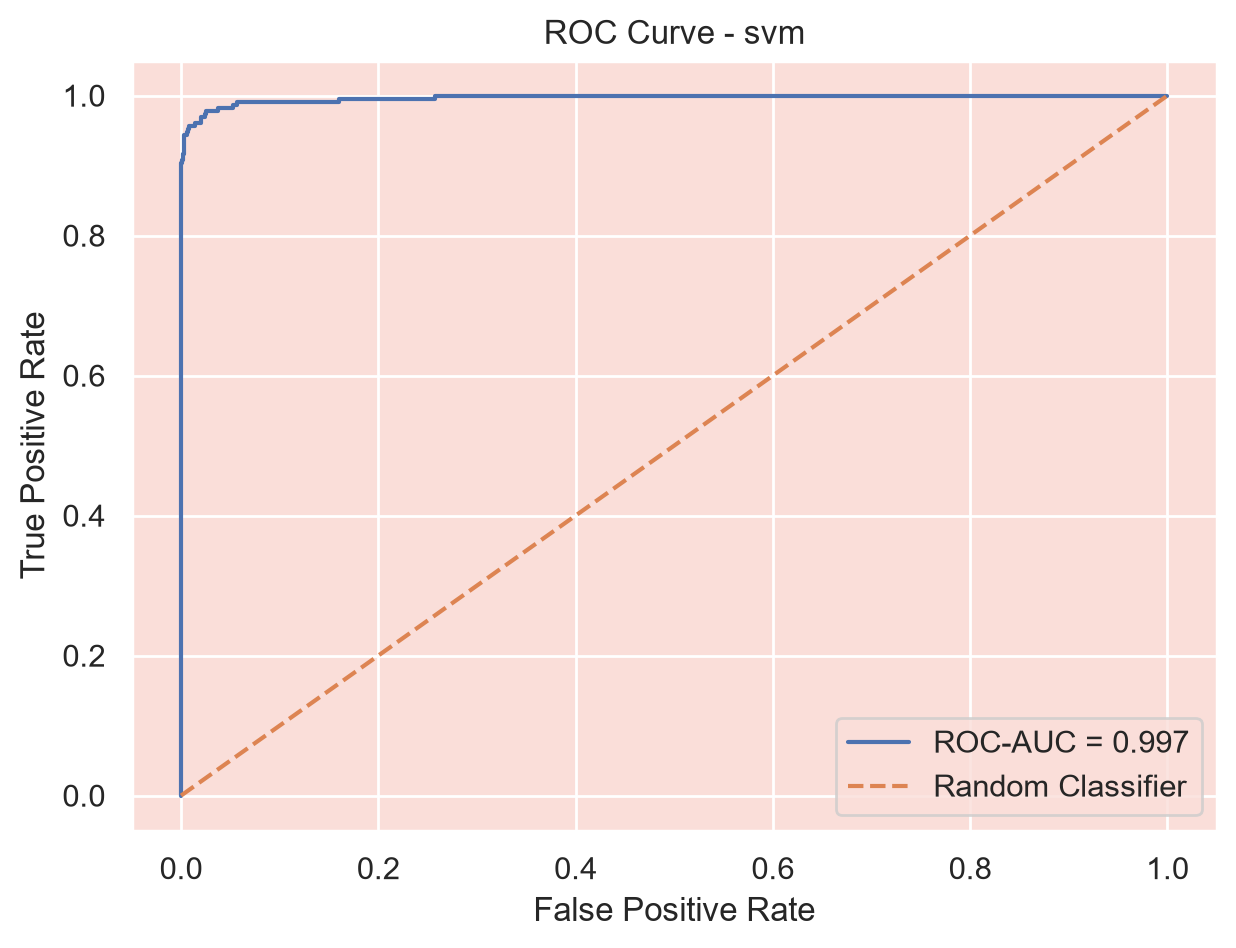

ROC-AUC: 0.9968809454921662
PR-AUC (Average Precision): 0.9853085520477235


In [69]:
# Predictions
y_pred = svm_model.predict(X_test)
y_prob = svm_model.predict_proba(X_test)[:, 1]

## Confusion Matrix
cm = confusion_matrix(y_test,y_pred)
print("Confusion Matrix:")
print(cm)

# Classification Report
print("\n Classification Report")
print(classification_report(y_test,y_pred))

## Individual Merics
print("Accuracy:",accuracy_score(y_test,y_pred))
print("Precision:",precision_score(y_test,y_pred))
print("f1 score:",f1_score(y_test,y_pred))
print("Recall:",recall_score(y_test,y_pred))

# ROC Curve and ROC-AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc= roc_auc_score(y_test,y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - svm")
plt.legend()
plt.show()

print("ROC-AUC:", roc_auc)

# PR-AUC
pr_auc = average_precision_score(y_test, y_prob)
print("PR-AUC (Average Precision):", pr_auc)



In [70]:
# Predictions on training data
y_train_pred = svm_model.predict(X_train)
y_train_prob = svm_model.predict_proba(X_train)[:, 1]

# Predictions on testing data
y_test_pred = svm_model.predict(X_test)
y_test_prob = svm_model.predict_proba(X_test)[:, 1]


# Function to calculate metrics
def evaluate_model(y_true, y_pred, y_prob):

    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1 Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }


# Evaluate both datasets
train_metrics = evaluate_model(
    y_train, y_train_pred, y_train_prob
)

test_metrics = evaluate_model(
    y_test, y_test_pred, y_test_prob
)


# Comparison table
comparison = pd.DataFrame({
    'Training Data': train_metrics,
    'Testing Data': test_metrics
})

print(comparison.round(4))

           Training Data  Testing Data
Accuracy          0.9846        0.9892
Precision         0.9051        0.9474
Recall            0.9497        0.9474
F1 Score          0.9269        0.9474
ROC-AUC           0.9967        0.9969
PR-AUC            0.9830        0.9853


In [71]:
# Hyperparameter grid
param_grid_svm = {
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__kernel': ['rbf', 'linear'],
    'classifier__gamma': ['scale', 'auto']
}

# Grid Search
grid_search_svm = GridSearchCV(
    estimator=svm_model,
    param_grid=param_grid_svm,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

# Train
grid_search_svm.fit(X_train, y_train)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.1, 1, ...], 'classifier__gamma': ['scale', 'auto'], 'classifier__kernel': ['rbf', 'linear']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_s

In [72]:
# Best parameters
print("Best Parameters:", grid_search_svm.best_params_)
print("Best CV F1 Score:", grid_search_svm.best_score_)

Best Parameters: {'classifier__C': 0.1, 'classifier__gamma': 'auto', 'classifier__kernel': 'rbf'}
Best CV F1 Score: 0.9545520976529944


In [73]:
best_svm = grid_search_svm.best_estimator_

y_pred_svm = best_svm.predict(X_test)
y_prob_svm = best_svm.predict_proba(X_test)[:, 1]

Confusion Matrix:
[[2000    1]
 [  20  208]]

Classification Report
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2001
           1       1.00      0.91      0.95       228

    accuracy                           0.99      2229
   macro avg       0.99      0.96      0.97      2229
weighted avg       0.99      0.99      0.99      2229

Accuracy: 0.990578734858681
Precision: 0.9952153110047847
F1 Score: 0.9519450800915332
Recall: 0.9122807017543859


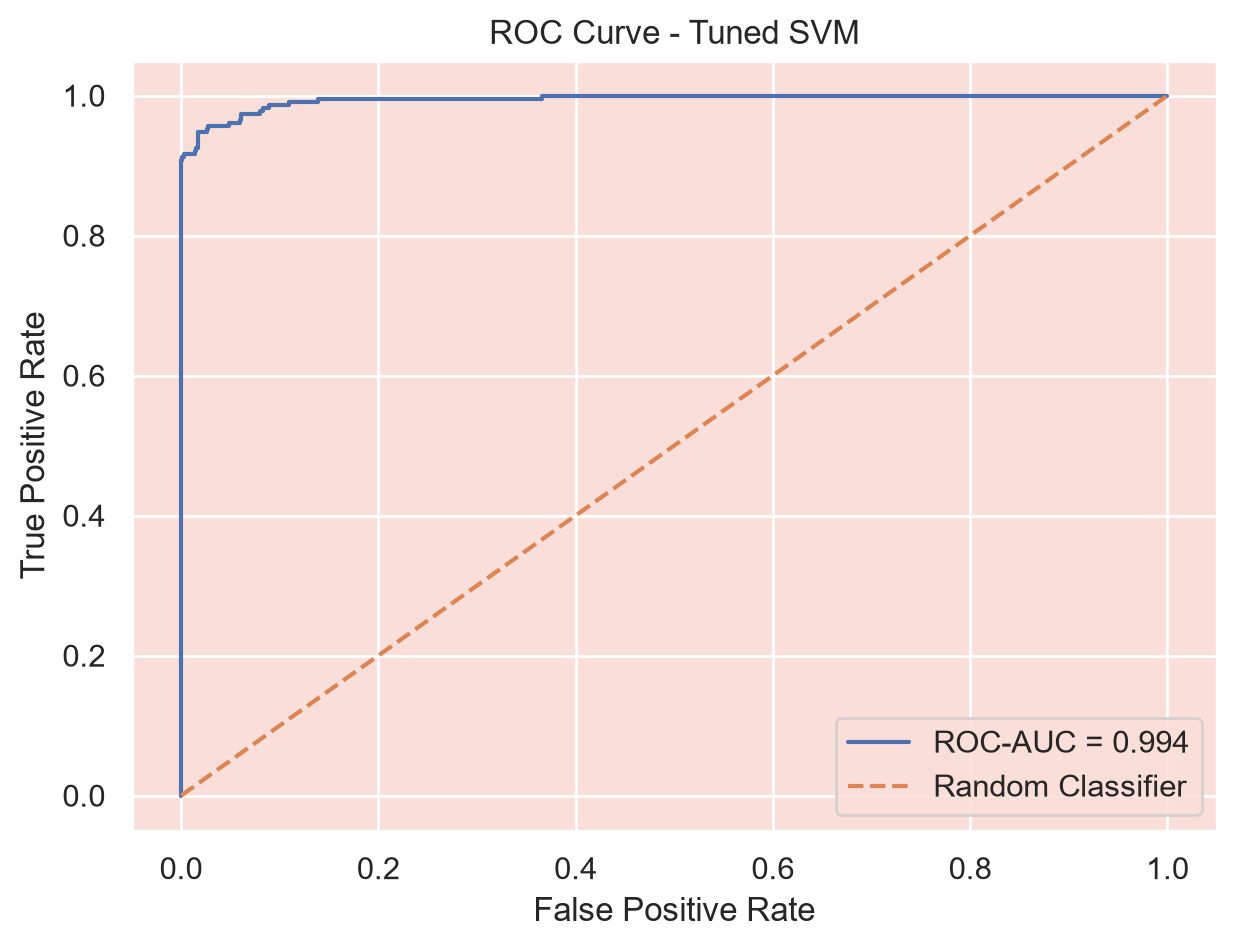

ROC-AUC: 0.994430416370762
PR-AUC: 0.9744453193433116


In [74]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_svm)
print("Confusion Matrix:")
print(cm)

# Classification Report
print("\nClassification Report")
print(classification_report(y_test, y_pred_svm))

# Individual Metrics
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("F1 Score:", f1_score(y_test, y_pred_svm))
print("Recall:", recall_score(y_test, y_pred_svm))

# ROC Curve and ROC-AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob_svm)
roc_auc = roc_auc_score(y_test, y_prob_svm)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--',
         label='Random Classifier')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned SVM")
plt.legend()
plt.show()

print("ROC-AUC:", roc_auc)

# PR-AUC
pr_auc = average_precision_score(y_test, y_prob_svm)
print("PR-AUC:", pr_auc)

In [75]:
## Random Forest model
# Preprocessing
rf_preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
        ('num', 'passthrough', num_features)
    ]
)

rf_model = Pipeline([
    ('preprocessor', rf_preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['step','type','amount','oldbalanceOrg','oldbalanceDest']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining c


Confusion Matrix:
 [[1999    2]
 [   4  224]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      2001
           1       0.99      0.98      0.99       228

    accuracy                           1.00      2229
   macro avg       0.99      0.99      0.99      2229
weighted avg       1.00      1.00      1.00      2229

Accuracy: 0.9973082099596231
Precision: 0.9911504424778761
Recall: 0.9824561403508771
F1 Score: 0.986784140969163
ROC-AUC: 0.9998542395468932
PR-AUC: 0.9987288910957204


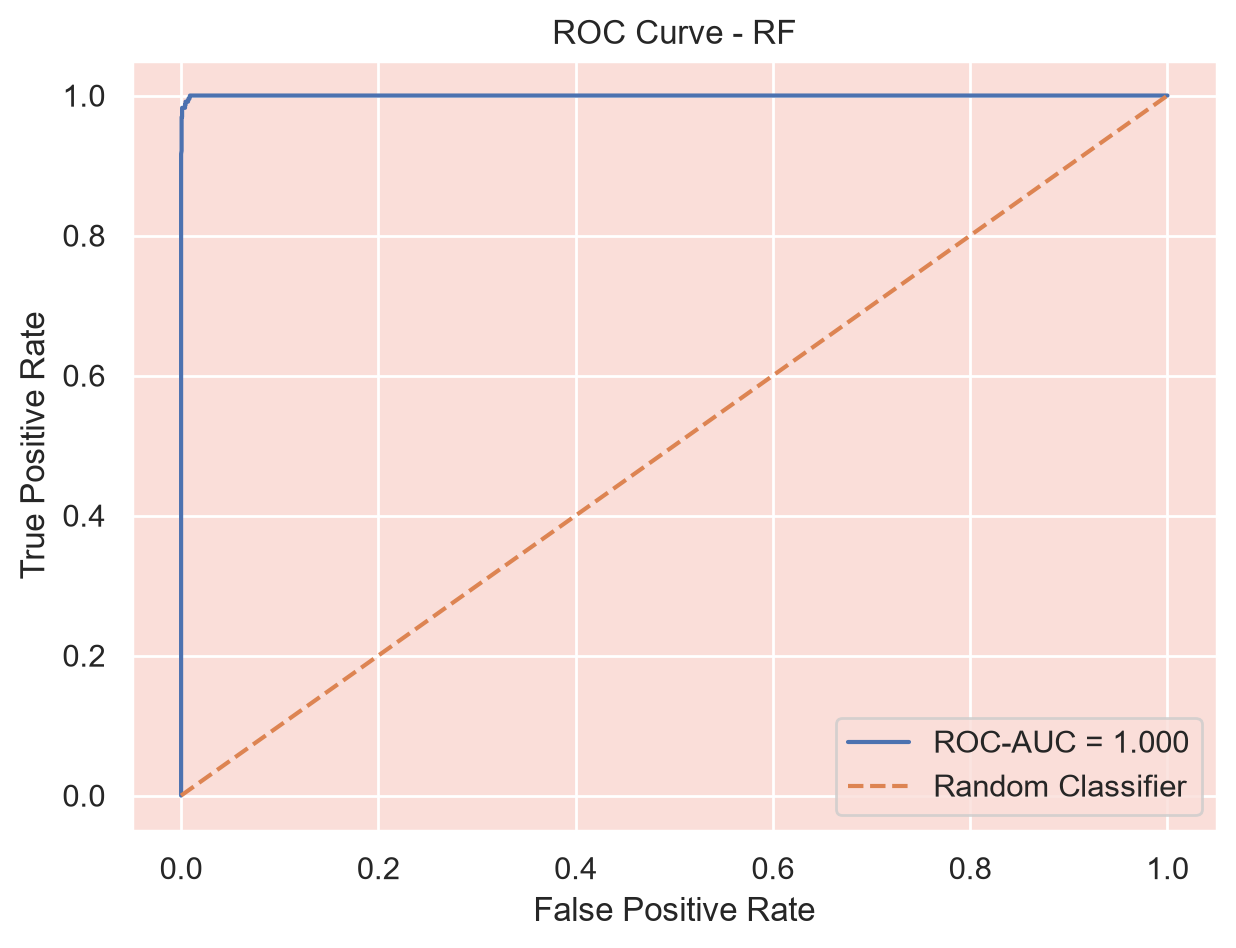

ROC-AUC: 0.9998542395468932
PR-AUC (Average Precision): 0.9987288910957204


In [76]:
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print("PR-AUC:", average_precision_score(y_test, y_prob_rf))

# ROC Curve and ROC-AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)
roc_auc= roc_auc_score(y_test,y_prob_rf)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - RF")
plt.legend()
plt.show()

print("ROC-AUC:", roc_auc)

# PR-AUC
pr_auc = average_precision_score(y_test, y_prob_rf)
print("PR-AUC (Average Precision):", pr_auc)



In [77]:
param_grid_rf = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [10, 15, 20, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 'log2']
}

grid_search_rf = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid_rf,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search_rf.fit(X_train, y_train)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [10, 15, ...], 'classifier__max_features': ['sqrt', 'log2'], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more abo

In [78]:
print("Best Parameters:", grid_search_rf.best_params_)
print("Best CV F1 Score:", grid_search_rf.best_score_)

Best Parameters: {'classifier__max_depth': 15, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 300}
Best CV F1 Score: 0.978080326640663


In [79]:
best_rf = grid_search_rf.best_estimator_

y_pred_rf = best_rf.predict(X_test)
y_prob_rf = best_rf.predict_proba(X_test)[:, 1]

Classification report:               precision    recall  f1-score   support

           0       1.00      1.00      1.00      2001
           1       0.99      0.98      0.99       228

    accuracy                           1.00      2229
   macro avg       0.99      0.99      0.99      2229
weighted avg       1.00      1.00      1.00      2229

Accuracy: 0.9973082099596231
Precision: 0.9911504424778761
Recall: 0.9824561403508771
F1 Score: 0.986784140969163
ROC-AUC: 0.9998531436036368
PR-AUC: 0.998750411480791


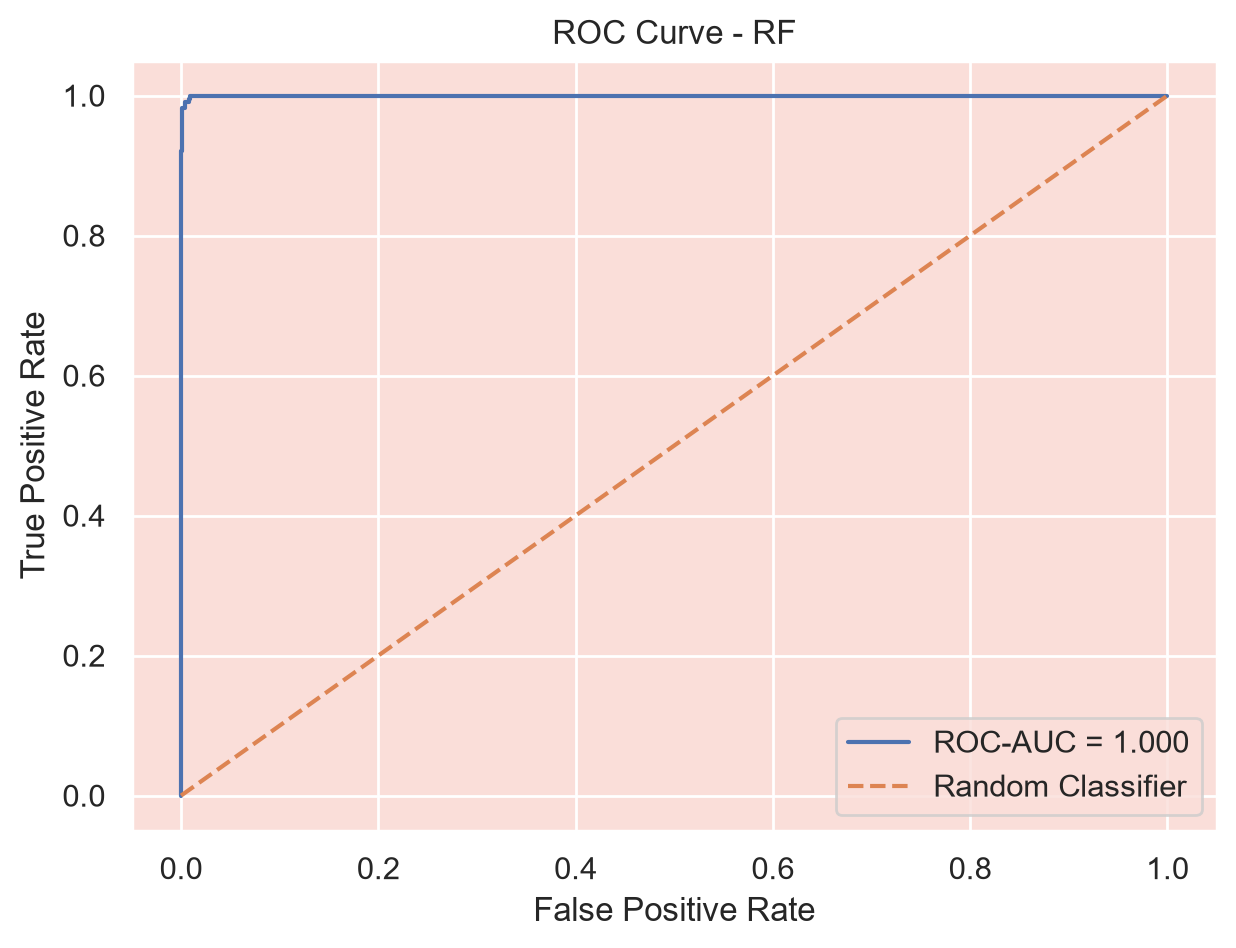

ROC-AUC: 0.9998531436036368
PR-AUC (Average Precision): 0.998750411480791


In [80]:
print("Classification report:", classification_report(y_test, y_pred_rf))

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print("PR-AUC:", average_precision_score(y_test, y_prob_rf))

# ROC Curve and ROC-AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)
roc_auc= roc_auc_score(y_test,y_prob_rf)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - RF")
plt.legend()
plt.show()

print("ROC-AUC:", roc_auc)

# PR-AUC
pr_auc = average_precision_score(y_test, y_prob_rf)
print("PR-AUC (Average Precision):", pr_auc)


In [81]:
##Decision tree Preprocessing
dt_preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
        ('num', 'passthrough', num_features)
    ]
)

In [82]:
## Decision Tree Pipeline
dt_model = Pipeline([
    ('preprocessor', dt_preprocessor),
    ('classifier', DecisionTreeClassifier(
        criterion='gini',
        max_depth=None,
        class_weight='balanced',
        random_state=42
    ))
])

In [83]:
# Fit the model
dt_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['step','type','amount','oldbalanceOrg','oldbalanceDest']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining c

Accuracy: 0.993719156572454
Precision: 0.9863636363636363
Recall: 0.9517543859649122
F1 Score: 0.96875
ROC-AUC: 0.9751275677950498
PR-AUC: 0.9437108654727482

Confusion Matrix:
 [[1998    3]
 [  11  217]]

Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      1.00      2001
           1       0.99      0.95      0.97       228

    accuracy                           0.99      2229
   macro avg       0.99      0.98      0.98      2229
weighted avg       0.99      0.99      0.99      2229



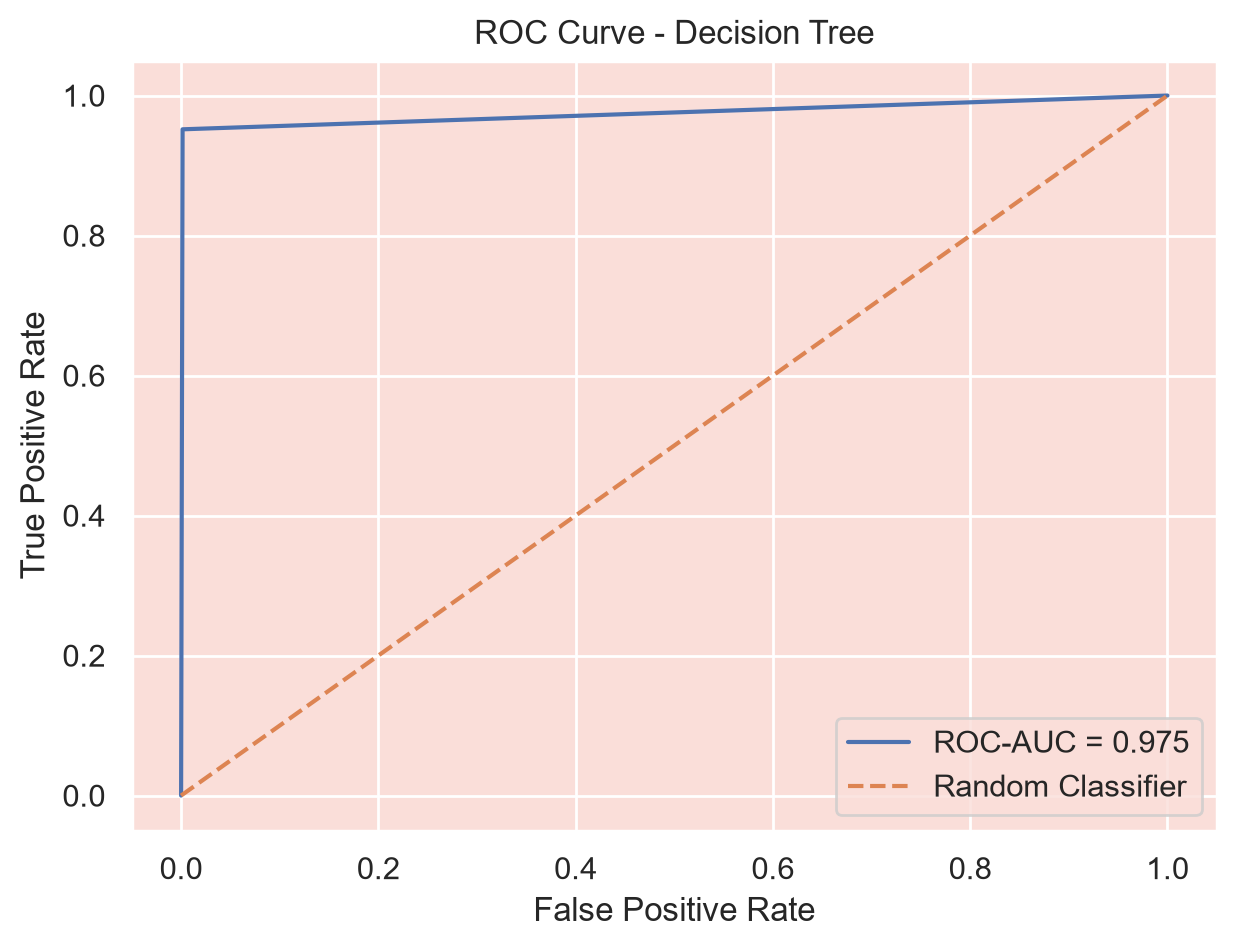

ROC-AUC: 0.9751275677950498
PR-AUC (Average Precision): 0.9437108654727482


In [84]:
#Prediction
y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]


## Evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt))
print("PR-AUC:", average_precision_score(y_test, y_prob_dt))

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))

# ROC Curve and ROC-AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob_dt)
roc_auc= roc_auc_score(y_test,y_prob_dt)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Decision Tree")
plt.legend()
plt.show()

print("ROC-AUC:", roc_auc)

# PR-AUC
pr_auc = average_precision_score(y_test, y_prob_dt)
print("PR-AUC (Average Precision):", pr_auc)


In [85]:
##Hyperparameter tuning using GridSearchCV
param_grid_dt = {
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_depth': [5, 10, 15, 20, None],
    'classifier__min_samples_split': [2, 5, 10, 20],
    'classifier__min_samples_leaf': [1, 2, 4, 8],
    'classifier__max_features': [None, 'sqrt']
}

grid_search_dt = GridSearchCV(
    estimator=dt_model,
    param_grid=param_grid_dt,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search_dt.fit(X_train, y_train)

Fitting 5 folds for each of 320 candidates, totalling 1600 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__criterion': ['gini', 'entropy'], 'classifier__max_depth': [5, 10, ...], 'classifier__max_features': [None, 'sqrt'], 'classifier__min_samples_leaf': [1, 2, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about 

In [86]:
print("Best Parameters:", grid_search_dt.best_params_)
print("Best CV F1 Score:", grid_search_dt.best_score_)

Best Parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 20, 'classifier__max_features': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5}
Best CV F1 Score: 0.9764485292254241


In [87]:
## Evaluate Tuned Decision Tree
best_dt = grid_search_dt.best_estimator_

y_pred_dt_tuned = best_dt.predict(X_test)
y_prob_dt_tuned = best_dt.predict_proba(X_test)[:, 1]

Accuracy: 0.9941677882458502
Precision: 0.9864253393665159
Recall: 0.956140350877193
F1 Score: 0.9710467706013363
ROC-AUC: 0.9773205502511902
PR-AUC: 0.947647386830016


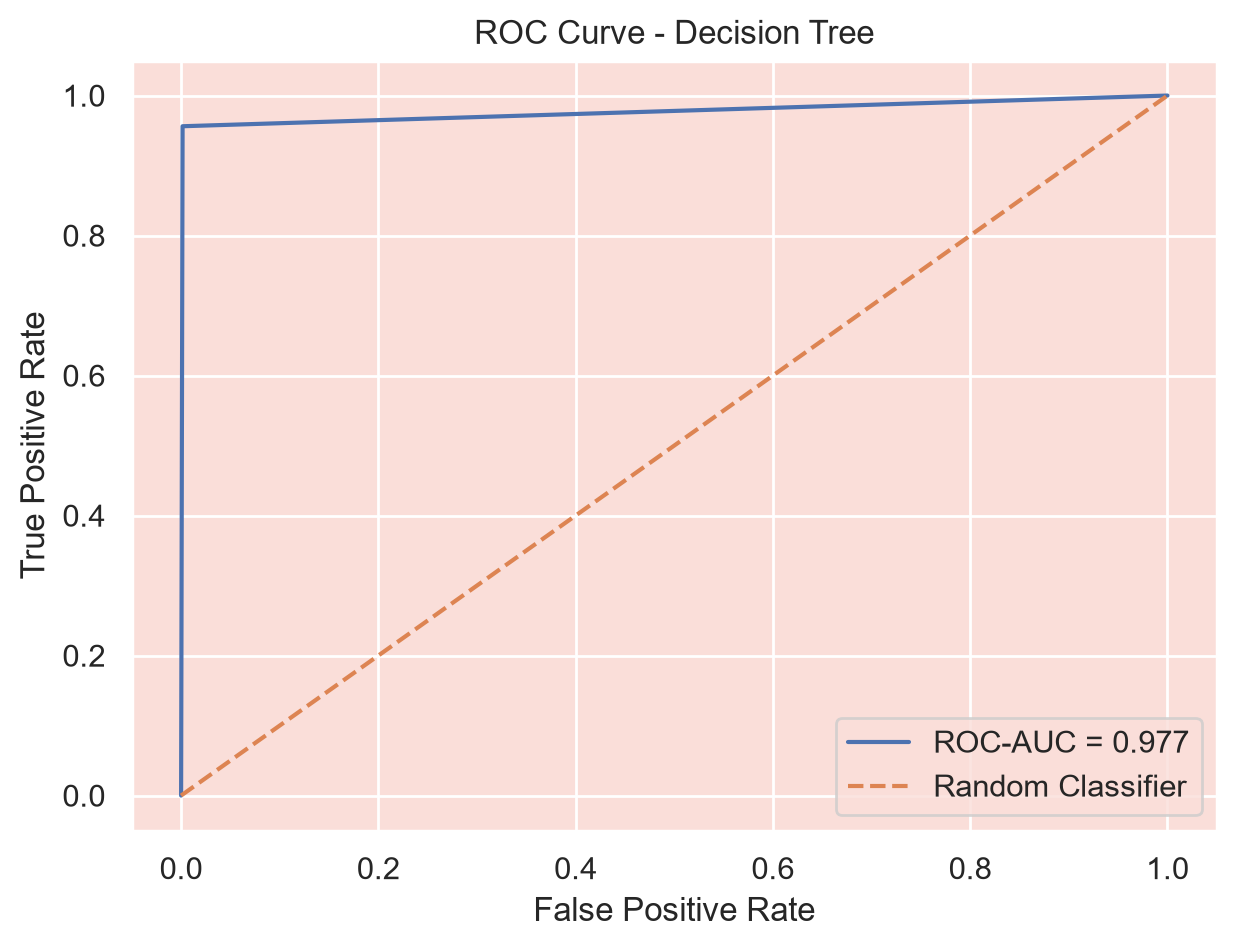

ROC-AUC: 0.9773205502511902
PR-AUC (Average Precision): 0.947647386830016


In [88]:
## Evaluation tuned metrics
print("Accuracy:", accuracy_score(y_test, y_pred_dt_tuned))
print("Precision:", precision_score(y_test, y_pred_dt_tuned))
print("Recall:", recall_score(y_test, y_pred_dt_tuned))
print("F1 Score:", f1_score(y_test, y_pred_dt_tuned))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt_tuned))
print("PR-AUC:", average_precision_score(y_test, y_prob_dt_tuned))

# ROC Curve and ROC-AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob_dt_tuned)
roc_auc= roc_auc_score(y_test,y_prob_dt_tuned)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Decision Tree")
plt.legend()
plt.show()

print("ROC-AUC:", roc_auc)

# PR-AUC
pr_auc = average_precision_score(y_test, y_prob_dt_tuned)
print("PR-AUC (Average Precision):", pr_auc)


In [89]:
##Gradient Boosting Preprocessing
gb_preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
        ('num', 'passthrough', num_features)
    ]
)

In [90]:
## Pipeline
gb_model = Pipeline([
    ('preprocessor', gb_preprocessor),
    ('classifier', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

In [91]:
#Train the Model
gb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['step','type','amount','oldbalanceOrg','oldbalanceDest']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining c

In [92]:
# Prediction

y_pred_gb = gb_model.predict(X_test)
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

# Evaluate the Model
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1 Score:", f1_score(y_test, y_pred_gb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_gb))
print("PR-AUC:", average_precision_score(y_test, y_prob_gb))

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_gb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_gb))

Accuracy: 0.9941677882458502
Precision: 1.0
Recall: 0.9429824561403509
F1 Score: 0.9706546275395034
ROC-AUC: 0.9996460103281692
PR-AUC: 0.9975376603331718

Confusion Matrix:
 [[2001    0]
 [  13  215]]

Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      1.00      2001
           1       1.00      0.94      0.97       228

    accuracy                           0.99      2229
   macro avg       1.00      0.97      0.98      2229
weighted avg       0.99      0.99      0.99      2229



In [93]:
## Hyperparameter Tuning of Gradient Boosting
param_grid_gb = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__learning_rate': [0.01, 0.05, 0.1],
    'classifier__max_depth': [2, 3, 4],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

grid_search_gb = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid_gb,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search_gb.fit(X_train, y_train)

Fitting 5 folds for each of 243 candidates, totalling 1215 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__learning_rate': [0.01, 0.05, ...], 'classifier__max_depth': [2, 3, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more abo

In [94]:
print("Best Parameters:", grid_search_gb.best_params_)
print("Best CV F1 Score:", grid_search_gb.best_score_)

Best Parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}
Best CV F1 Score: 0.9811215855466282


Accuracy: 0.996859578286227
Precision: 0.9955156950672646
Recall: 0.9736842105263158
F1 Score: 0.9844789356984479

Confusion Matrix:
[[2000    1]
 [   6  222]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2001
           1       1.00      0.97      0.98       228

    accuracy                           1.00      2229
   macro avg       1.00      0.99      0.99      2229
weighted avg       1.00      1.00      1.00      2229



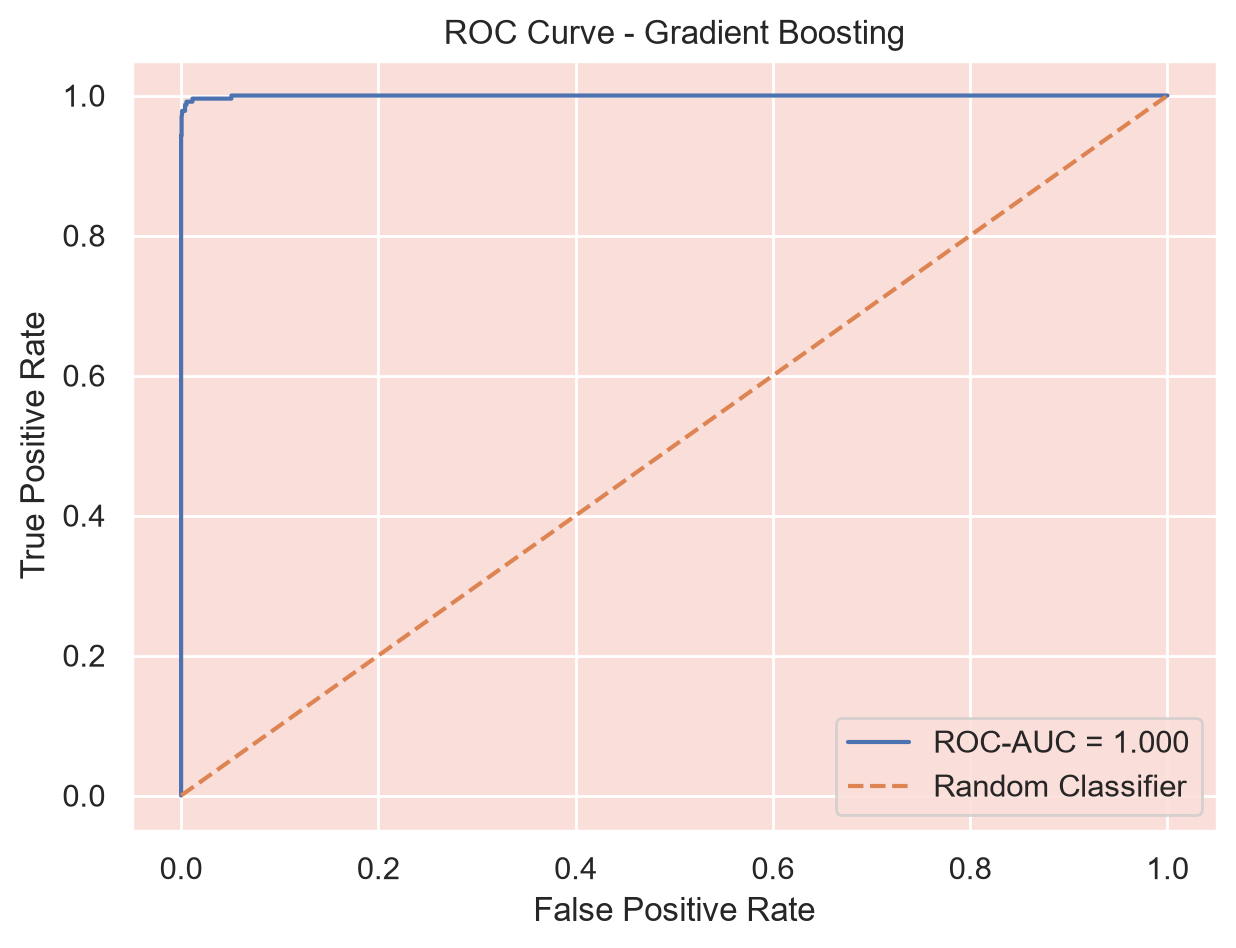

ROC-AUC: 0.9996460103281692
PR-AUC (Average Precision): 0.9975376603331718


In [95]:
best_gb = grid_search_gb.best_estimator_


# Predictions on testing data
y_pred_gb = best_gb.predict(X_test)

# Evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1 Score:", f1_score(y_test, y_pred_gb))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

# ROC Curve and ROC-AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob_gb)
roc_auc= roc_auc_score(y_test,y_prob_gb)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Gradient Boosting")
plt.legend()
plt.show()

print("ROC-AUC:", roc_auc)

# PR-AUC
pr_auc = average_precision_score(y_test, y_prob_gb)
print("PR-AUC (Average Precision):", pr_auc)



In [96]:
best_logistic = grid_search.best_estimator_
best_svm = grid_search_svm.best_estimator_
best_rf = grid_search_rf.best_estimator_
best_dt = grid_search_dt.best_estimator_
best_gb = grid_search_gb.best_estimator_

In [97]:
models = {
    'Logistic Regression': best_logistic,
    'SVM': best_svm,
    'Random Forest': best_rf,
    'Decision Tree': best_dt,
    'Gradient Boosting': best_gb
}
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
import pandas as pd

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'PR-AUC': average_precision_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(results)

print(comparison_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  PR-AUC
0  Logistic Regression    0.9879     1.0000  0.8816    0.9371   0.9590  0.9282
1                  SVM    0.9906     0.9952  0.9123    0.9519   0.9944  0.9744
2        Random Forest    0.9973     0.9912  0.9825    0.9868   0.9999  0.9988
3        Decision Tree    0.9942     0.9864  0.9561    0.9710   0.9773  0.9476
4    Gradient Boosting    0.9969     0.9955  0.9737    0.9845   0.9997  0.9978


In [98]:
##. Sort models by F1-score
comparison_df.sort_values(
    by='F1 Score',
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
2,Random Forest,0.997308,0.991150,0.982456,0.986784,0.999853,0.998750
4,Gradient Boosting,0.996860,0.995516,0.973684,0.984479,0.999684,0.997818
3,Decision Tree,0.994168,0.986425,0.956140,0.971047,0.977321,0.947647
1,SVM,0.990579,0.995215,0.912281,0.951945,0.994430,0.974445
0,Logistic Regression,0.987887,1.000000,0.881579,0.937063,0.958990,0.928178


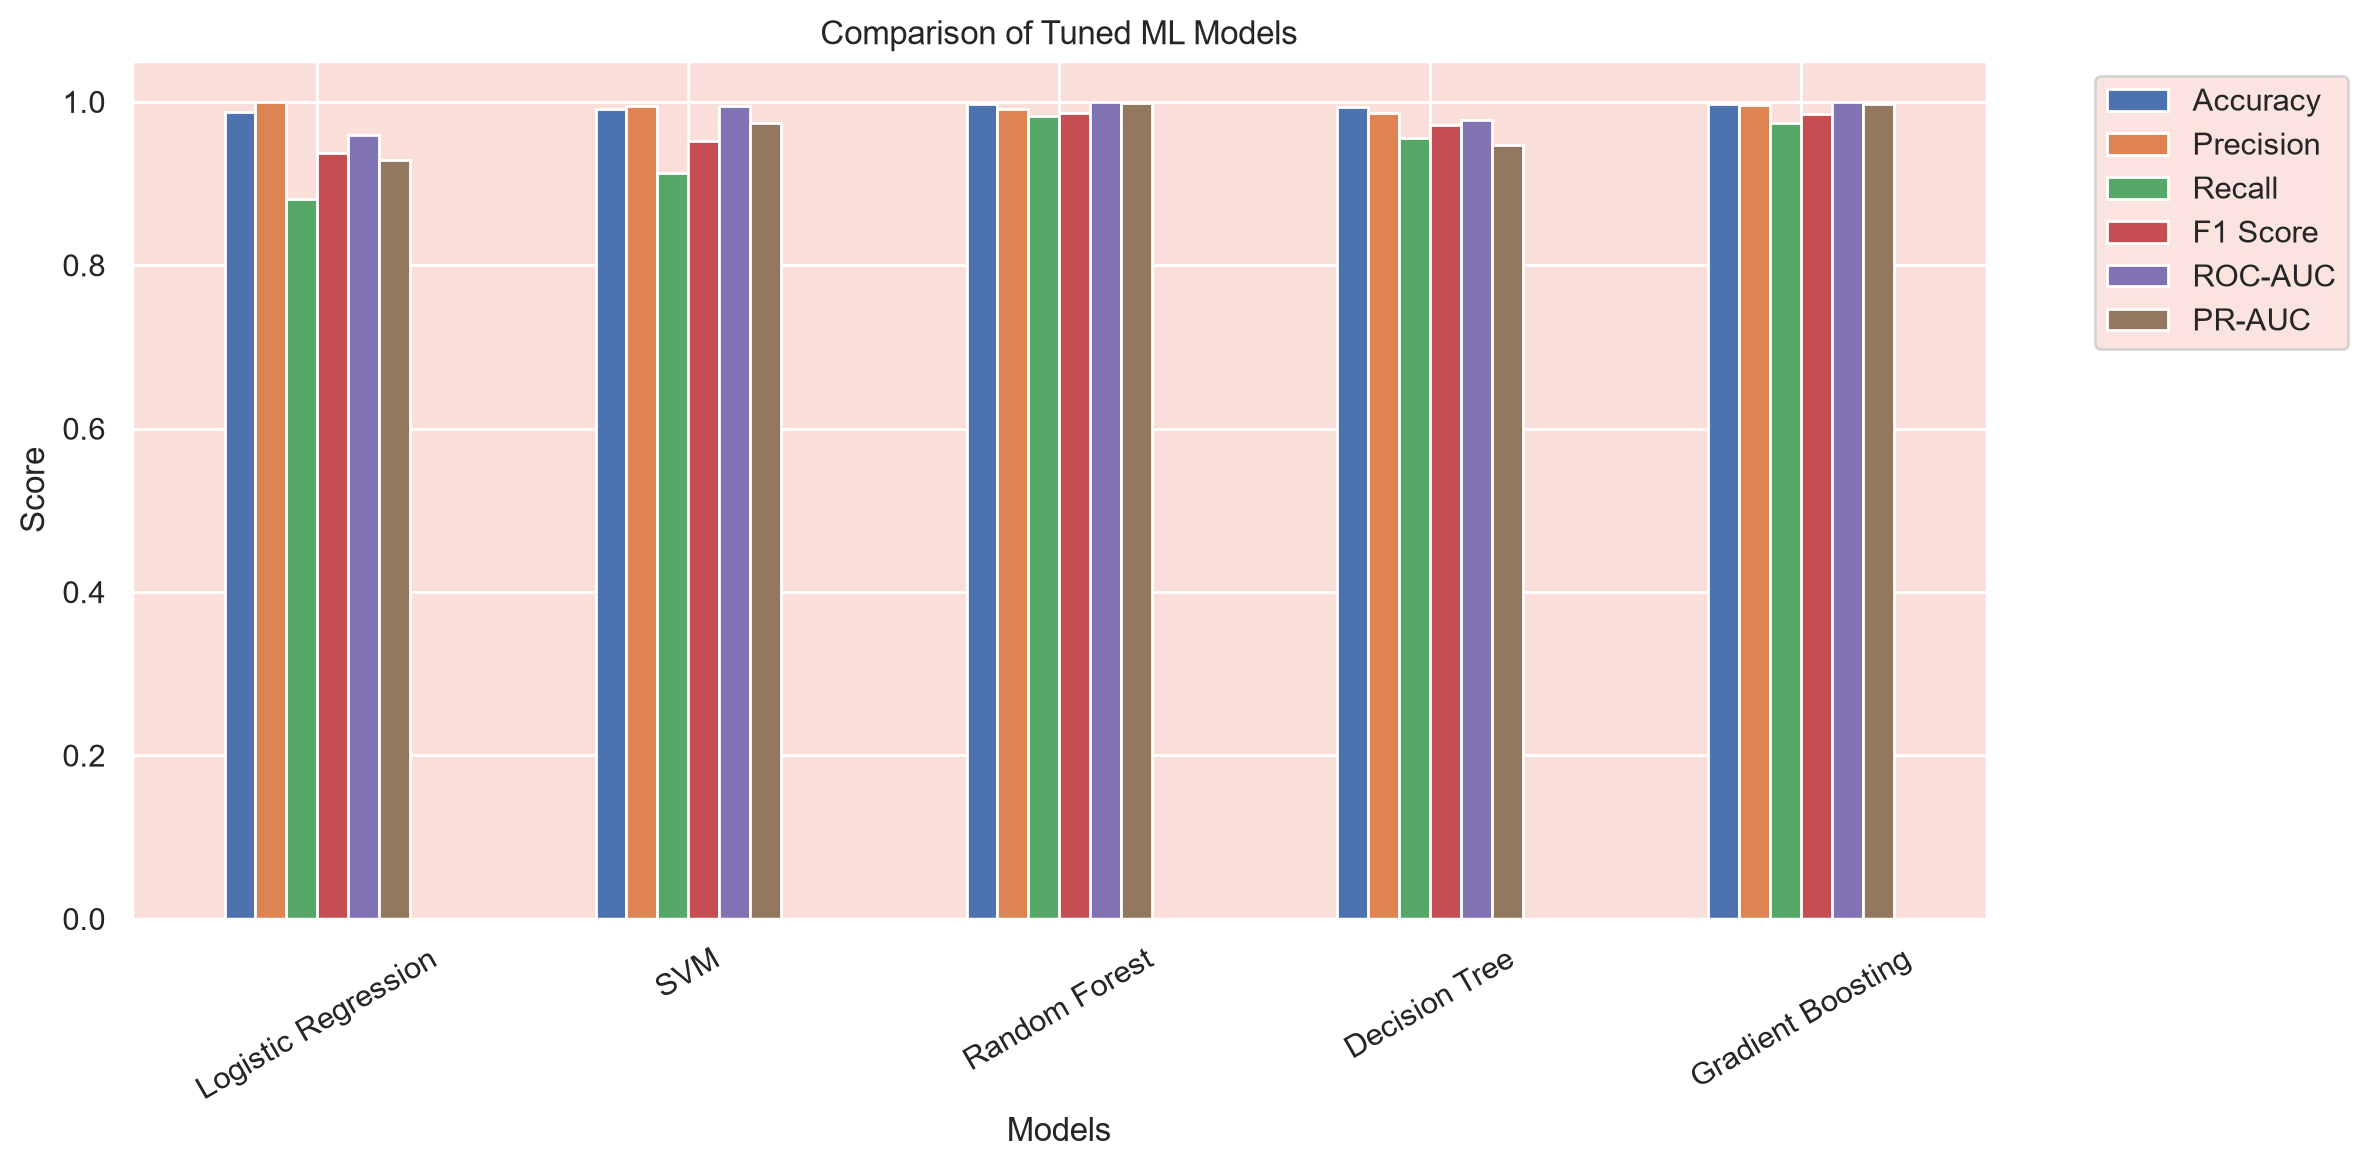

In [99]:
##Visual comparison
comparison_df.set_index('Model').plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Comparison of Tuned ML Models')
plt.ylabel('Score')
plt.xlabel('Models')
plt.xticks(rotation=30)
plt.legend(bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

## Inferences:
- All five models were able to identify fraudulent transactions to different levels.
- Random Forest achieved the highest F1-score of 98.68%.
- Random Forest also achieved the highest recall of 98.25%, meaning it identified most fraudulent transactions.
- Gradient Boosting achieved the highest precision of 99.55%, meaning its fraud predictions were highly accurate.
- Decision Tree also performed well, with an F1-score of 97.10%.
- Logistic Regression achieved 100% precision but had a lower recall of 88.16%.
- SVM achieved a high recall but lower precision, meaning it identified most fraud cases but also incorrectly flagged more genuine transactions.

## Final Model Comparison
Random Forest:
- Highest F1-score among all five models.
- High precision and recall.
- Very strong ROC-AUC and PR-AUC scores.
- Provides a good balance between identifying fraud and avoiding incorrect fraud predictions.
- 
Gradient Boosting:
- Highest precision among all models.
- Very high recall and F1-score.
- Performs almost as well as Random Forest.
- 
Decision Tree:
- Good performance with high precision and recall.
- Slightly lower overall performance than Random Forest and Gradient Boosting.
- 
Logistic Regression:
- Provides a simple and understandable baseline model.
- High precision but misses more fraudulent transactions than the top-performing models.
- 
SVM:
- Identifies most fraudulent transactions.
- However, its lower precision means it generates more false fraud alerts.
- 
Best performing model: Random Forest
Random Forest is the best-performing model based on the F1-score in our current comparison. It provides a good balance between precision and recall.

In [100]:
import joblib

In [101]:
MODEL_FILE="Fraud_Detection_System.joblib"
joblib.dump(best_rf,MODEL_FILE)

['Fraud_Detection_System.joblib']